# 04 — Modeling, evaluation and business translation (F1 · F2 · F3)

**Single official stage-F notebook** (v3.1, 19/10/2026). It replaces `04_modeling_evaluation.ipynb` (v1) and `04_modeling_evaluation_v2.ipynb` (v2), which have been removed from this distribution along with the ablation and Kaggle-style notebooks.

| Stage | Question | Sections |
|---|---|---|
| **F1** | Time contract, baselines, models, tuning | 1–4 |
| **F2** | Model choice, probability quality, operating policy, test evaluation, robustness, explanation | 5–9 |
| **F3** | What the scores mean for the hotel: queue, tiers, revenue at risk, action schedule, group track, hand-over to G | 10–12 |

**What changed versus v1/v2 (why the earlier results looked wrong).**
1. *Alert policy.* v1 froze an F1-max threshold (51% of validation flagged → 60% of test); v2 froze a probability that flagged 20% of validation and **66.7% of test**. The policy is now **capacity-based**: the top k% of each weekly batch of new bookings, so the queue size is fixed by design; a fixed probability cut-off is a diagnostic only.
2. *Probabilities.* No class weighting; calibration only if it improves pre-test evidence.
3. *Time contract.* Folds follow `docs/F1_validation_design.md` (three 2016 quarters, final fit 2016-12-31); the top-15 agent list is learned **inside** every fold.
4. *Features.* All price-derived inputs excluded together (`adr_clean`, `adr_vs_ref`, `adr_per_guest`, `is_free_rate`); missing configured features raise an error.

**What changed in v3.1 (fixes Fv3-01…14).** Data, folds, tuning, the selected model and the headline arrival-cohort metrics are unchanged; what changed is the time contract of everything downstream.
- **Two separated views.** (a) *Retrospective arrival-cohort evaluation* (headline metrics, cohort top-k, deciles, robustness): evaluation only. (b) *Operational queue simulation*: a booking is scored at the **end of its booking week** (decision time) by a model whose fit date and selection cutoff are before that time, and only if it is still eligible then (created, not cancelled, not arrived, not complimentary; consent / open action are unknown, never assumed). `risk_scores.csv`, tiers, the action queue and schedule, workload and the weekly-policy metrics come only from (b) (Fv3-01, 03).
- **One canonical score / tier table** per run (`booking_id` + `score_time` + `run_id`); every output joins it and the notebook asserts that p / tier / rule agree across the files (Fv3-02).
- **Ties broken by a hash of `booking_id`** (row order never matters); **floor** rounding of capacity slots per batch (Fv3-08).
- **Two-track scorer** `fm.score_bookings` (population rule, group rule, time and eligibility checks) stored in the bundle (Fv3-09); dated action schedule with the immediate-reminder rule (Fv3-13).
- **`pre_arrival` H = 14 / 30 selected on their own folds**, with selection evidence truncated at the branch cutoff (Fv3-04); the booking-date view is renamed and combined with population rule B (Fv3-12).
- The sum of p per arrival week is a **retrospective aggregate** (bookings, not rooms) with a same-population baseline (Fv3-05, 07); cancellations after the H mark are counted in full (Fv3-06); odds ratios against a stated reference category (Fv3-14); wording fixes (Fv3-10, 11 in `src/run_notebooks.py`).

**Caveats that stay.** The extract is a near-arrival PMS snapshot (retrospective prototype, README §6.2). The 2017 test cohort is a *partially explored* holdout (notebook 03 EDA and earlier versions saw its labels); "scored once" describes the flow of one run of this notebook, not an untouched holdout. Fold 3 is used both in tuning and in the calibration choice, so that choice is cross-validated evidence, not an independent validation.

In [1]:
import json, platform, sys, time, warnings
from pathlib import Path
from importlib.metadata import version

import joblib
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score, brier_score_loss, log_loss, roc_auc_score

ROOT = Path.cwd()
while not (ROOT / 'data' / 'processed' / 'modeling_dataset.csv').exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError('Run this notebook inside the repository.')
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
import f_modeling as fm

warnings.filterwarnings('ignore', category=UserWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style='whitegrid')
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)

CONFIG = {
    'seed': 42,
    'population': 'individual',
    'population_block_size': 5,                           # rule A: Groups OR Non Refund OR dup_group_size >= 5 (notebook 03)
    'fit_date_final': '2016-12-31',                       # booking_time final model = its selection cutoff (F1 design §3)
    'folds': [                                            # (name, fit date, validate from, validate to)
        ('fold_1', '2016-03-31', '2016-04-01', '2016-06-30'),
        ('fold_2', '2016-06-30', '2016-07-01', '2016-09-30'),
        ('fold_3', '2016-09-30', '2016-10-01', '2016-12-31'),
    ],
    'test_window': ('2017-01-01', '2017-08-31'),
    'excluded_price_features': ['adr_clean', 'adr_vs_ref', 'adr_per_guest', 'is_free_rate'],
    'top_agents': 15,
    'optuna_trials': {'logistic_regression': 20, 'xgboost': 30},
    'pre_arrival_trials': {'logistic_regression': 8, 'xgboost': 15},   # own selection per H branch (F1 design §3)
    'half_life_grid_days': [0, 365, 180, 90],             # 0 = no recency weighting
    'selection_tolerance_logloss': 0.002,                 # within this, prefer the simpler model
    'calibration_tolerance_brier': 0.0005,                # within this, keep raw probabilities
    'capacity_shares': [0.05, 0.10, 0.20],
    'tier_high_share': 0.05, 'tier_medium_share': 0.20,   # risk_tier: high = top 5%, medium = 5-20% of a batch
    'capacity_rounding': 'floor',                         # slots per batch = floor(share x batch size): the share is a hard ceiling
    'scoring_batch': 'booking week (W-SUN)',
    'decision_time': 'end of the booking week (Sunday); queue = bookings created that week and still eligible then',
    'i2_milestones_days': [30, 14], 'i2_max_messages': 2, 'i1_reminder_days': 7,
    'pre_arrival_horizons_days': [14, 30],
    'bootstrap_draws': 500,
    'min_alerts_for_precision': 30,
    'model_version': 'f-v3.1-2026-10-19',
}
SEED = CONFIG['seed']
np.random.seed(SEED)
OUT_ROOT = ROOT / 'artifacts' / 'modeling'
RUN_ID = CONFIG['model_version'] + '_' + pd.Timestamp.now().strftime('%Y%m%d-%H%M%S')
OUT = OUT_ROOT / 'runs' / RUN_ID          # every file of this run goes here; copied to OUT_ROOT (= latest) at the end
OUT.mkdir(parents=True, exist_ok=True)
print('Run id:', RUN_ID)
PACKAGES = ['pandas', 'numpy', 'scikit-learn', 'xgboost', 'optuna', 'scipy', 'matplotlib', 'seaborn']
ENV = {'python': platform.python_version(), **{p: version(p) for p in PACKAGES}}
print('Root:', ROOT); print(ENV)

C:\Users\ADMIN\AppData\Local\Temp\fenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Run id: f-v3.1-2026-10-19_20261020-101915
Root: C:\Users\ADMIN\Desktop\BA-Advance-Project---Group-2-main
{'python': '3.13.7', 'pandas': '2.2.3', 'numpy': '2.1.3', 'scikit-learn': '1.6.1', 'xgboost': '3.4.1', 'optuna': '4.9.0', 'scipy': '1.18.1', 'matplotlib': '3.10.0', 'seaborn': '0.13.2'}


## 1. Data, populations and features (F1)

`modeling_dataset.csv` (notebook 03, 78,892 rows after the data-quality filter) is joined on `booking_id` with three columns of `bookings_prepared.csv`: `agent_id` (to rebuild the top-agent list inside each fold) and `reservation_status` / `reservation_status_date` (used **only** for the `pre_arrival` eligibility filter and the label-known date, never as features).

In [2]:
df = pd.read_csv(ROOT / 'data/processed/modeling_dataset.csv', parse_dates=['arrival_date', 'booking_date'])
prep = pd.read_csv(ROOT / 'data/processed/bookings_prepared.csv',
                   usecols=['booking_id', 'agent_id', 'reservation_status', 'reservation_status_date'],
                   parse_dates=['reservation_status_date'], dtype={'agent_id': str})
df = df.merge(prep, on='booking_id', how='left', validate='one_to_one')
assert len(df) == 78_892 and df['agent_id'].notna().all()
df['label_known_date'] = np.where(df['reservation_status'].eq('Canceled'), df['reservation_status_date'], df['arrival_date'])
df['label_known_date'] = pd.to_datetime(df['label_known_date'])
df['booking_week'] = df['booking_date'].dt.to_period('W-SUN').astype(str)
df['arrival_week'] = df['arrival_date'].dt.to_period('W-SUN').astype(str)
df['arrival_month'] = df['arrival_date'].dt.to_period('M').astype(str)
df['tie'] = fm.id_tie_breaker(df['booking_id'])     # tie-break key fixed per booking_id: rankings never depend on row order
assert (fm.assign_population(df, 'A', CONFIG['population_block_size']) == df['population']).all(), 'population rule A not reproduced'

cfg = json.loads((ROOT / 'config/column_groups.json').read_text(encoding='utf-8'))
ind_cfg = cfg['individual_model']
excluded = set(CONFIG['excluded_price_features']) | set(cfg['excluded_features'])
NUM = [c for c in ind_cfg['numeric'] if c not in excluded]
CAT = [c for c in ind_cfg['categorical'] if c != 'agent_top']          # agent_top is rebuilt from agent_id per fold
PRE = list(ind_cfg['pre_arrival_extra'])
FEATURES = NUM + CAT + ['agent_id']
missing = [c for c in NUM + CAT + PRE + ['agent_id'] if c not in df.columns]
if missing:
    raise KeyError(f'Configured features missing from the data: {missing}')
forbidden = set(cfg['ops_only_cols']) | set(cfg['excluded_features']) | {c for c in df.columns if c.startswith('syn_')}
assert not (set(FEATURES) & forbidden), 'forbidden column used as a feature'
print(f'{len(NUM)} numeric + {len(CAT)} categorical + agent_id (top-{CONFIG["top_agents"]} rebuilt per fold)')
print('Price-derived inputs excluded (snapshot ADR, not the rate quoted at booking):', CONFIG['excluded_price_features'])

ind = df[df['population'].eq('individual')].copy()
grp = df[df['population'].eq('group_block')].copy()
test_lo, test_hi = CONFIG['test_window']
is_test = lambda f: f['arrival_date'].between(test_lo, test_hi)
summary = pd.DataFrame([
    {'population': name, 'part': part, 'bookings': len(f), 'cancel_rate': f['is_canceled'].mean() if part != 'test 2017' else np.nan}
    for name, frame in [('individual', ind), ('group_block', grp)]
    for part, f in [('2015-2016', frame[~is_test(frame)]), ('test 2017', frame[is_test(frame)])]])
display(summary.round(3))
print('Test labels stay unread until section 7.')

32 numeric + 6 categorical + agent_id (top-15 rebuilt per fold)
Price-derived inputs excluded (snapshot ADR, not the rate quoted at booking): ['adr_clean', 'adr_vs_ref', 'adr_per_guest', 'is_free_rate']


,population,part,bookings,cancel_rate
0,individual,2015-2016,32277,0.280
1,individual,test 2017,20399,NaN
2,group_block,2015-2016,19219,0.642
3,group_block,test 2017,6997,NaN


Test labels stay unread until section 7.


### 1.1 Time contract (F1 design §2–3)
Expanding-window folds inside 2016; every fitted step (imputers, scaler, encoders, **top-agent list**) is refit on the fold's training rows. A training row must have arrival **and** label-known date on or before the fold's fit date (label maturity; Canceled → `reservation_status_date`, otherwise arrival, by convention). The quarter-4 2015 fold of v1/v2 is dropped: it had only 2.5–3.9k training rows and an atypical AP (0.75–0.81 vs ~0.42 elsewhere) that dominated the tuning objective.

In [3]:
def train_rows(frame, fit_date):
    fit_date = pd.Timestamp(fit_date)
    rows = frame[frame['arrival_date'].le(fit_date)]
    assert rows['label_known_date'].le(fit_date).all(), 'label not known at the fit date'
    return rows

FOLDS = []
for name, fit_date, v0, v1 in CONFIG['folds']:
    tr = train_rows(ind, fit_date)
    va = ind[ind['arrival_date'].between(v0, v1)]
    assert tr['arrival_date'].max() < va['arrival_date'].min()
    FOLDS.append({'name': name, 'fit_date': fit_date, 'train': tr, 'valid': va})
display(pd.DataFrame([{'fold': f['name'], 'fit_date': f['fit_date'], 'train_rows': len(f['train']),
                       'valid_rows': len(f['valid']), 'valid_from': f['valid']['arrival_date'].min().date(),
                       'valid_to': f['valid']['arrival_date'].max().date(),
                       'valid_cancel_rate': round(f['valid']['is_canceled'].mean(), 3)} for f in FOLDS]))
OOF = pd.concat([f['valid'].assign(fold=f['name']) for f in FOLDS])
y_oof = OOF['is_canceled'].to_numpy()
tie_oof = OOF['tie'].to_numpy()

,fold,fit_date,train_rows,valid_rows,valid_from,valid_to,valid_cancel_rate
0,fold_1,2016-03-31,10637,6803,2016-04-01,2016-06-30,0.287
1,fold_2,2016-06-30,17440,7978,2016-07-01,2016-09-30,0.303
2,fold_3,2016-09-30,25418,6859,2016-10-01,2016-12-31,0.328


### 1.2 Leakage test for the agent mapping
The top-agent list must depend **only** on the training rows of each fold. Test: (1) the list learned inside a fitted fold pipeline equals the list computed from that fold's training rows alone; (2) changing the agents of every booking **after** the fit date does not change it. For comparison, the table counts how many fold training rows would get a different category from notebook 03's `agent_top` column, whose list was fitted on all arrivals up to 2016-12-31 (the leak fixed here).

In [4]:
AGENT_TEST = []
for f in FOLDS:
    pipe = fm.build_pipeline('logistic_regression', NUM, CAT, {'C': 1.0}, seed=SEED, top_agents=CONFIG['top_agents'])
    pipe.fit(f['train'][FEATURES], f['train']['is_canceled'])
    learned = pipe.named_steps['preprocess'].named_transformers_['agent'].named_steps['top'].top_agents_
    expected = fm.TopAgentEncoder(CONFIG['top_agents']).fit(f['train'][['agent_id']]).top_agents_
    assert learned == expected, 'top-agent list does not come from the fold training rows only'
    future = ind[ind['arrival_date'] > pd.Timestamp(f['fit_date'])]
    shuffled = pd.concat([f['train'], future.assign(agent_id='999')])
    after = fm.TopAgentEncoder(CONFIG['top_agents']).fit(shuffled[shuffled['arrival_date'] <= pd.Timestamp(f['fit_date'])][['agent_id']]).top_agents_
    assert after == learned, 'future rows changed the mapping'
    fold_cat = fm.TopAgentEncoder(CONFIG['top_agents']).fit(f['train'][['agent_id']]).transform(f['train'][['agent_id']]).ravel()
    AGENT_TEST.append({'fold': f['name'], 'fit_date': f['fit_date'], 'top_agents_in_fold': len(learned),
                       'agents_in_nb03_list_not_in_fold_list': len(set(f['train']['agent_top']) - set(learned) - {'other', 'none'}),
                       'train_rows_whose_nb03_category_differs': int((fold_cat != f['train']['agent_top'].astype(str).to_numpy()).sum()),
                       'test_passed': True})
AGENT_TEST = pd.DataFrame(AGENT_TEST)
display(AGENT_TEST)
print('Agent mapping leakage test passed for every fold.')

,fold,fit_date,top_agents_in_fold,agents_in_nb03_list_not_in_fold_list,train_rows_whose_nb03_category_differs,test_passed
0,fold_1,2016-03-31,15,3,794,True
1,fold_2,2016-06-30,15,3,1151,True
2,fold_3,2016-09-30,15,4,1623,True


Agent mapping leakage test passed for every fold.


## 2. Baselines (F1)
Fitted on the same fold training rows as the models, scored out-of-fold:
- **constant**: training cancellation rate;
- **rule_lead_time**: rank by lead time (longer = riskier);
- **rule_segment_x_leadband**: historical rate per market segment × lead-time band (shrunk to the segment rate) — a rule the hotel could run in a spreadsheet;
- **baseline_logistic**: logistic regression on lead time + market segment (README §6.2 / F1 design §4).

In [5]:
def oof_predict(make_scores):
    """make_scores(train_frame, valid_frame, fit_date) -> scores; returns OOF scores in OOF row order."""
    return np.concatenate([make_scores(f['train'], f['valid'], f['fit_date']) for f in FOLDS])

def base_lr(tr, va, fit_date):
    pipe = fm.build_pipeline('baseline_logistic', ['lead_time'], ['market_segment'], seed=SEED)
    return fm.fit_pipeline(pipe, tr, ['lead_time', 'market_segment'], fit_date).predict_proba(va[['lead_time', 'market_segment']])[:, 1]

OOF_SCORES = {
    'constant': oof_predict(lambda tr, va, d: np.full(len(va), tr['is_canceled'].mean())),
    'rule_lead_time': oof_predict(lambda tr, va, d: va['lead_time'].to_numpy(dtype=float)),
    'rule_segment_x_leadband': oof_predict(lambda tr, va, d: fm.RateTableRule(['market_segment', 'lead_band']).fit(tr).predict(va)),
    'baseline_logistic': oof_predict(base_lr),
}
def fold_table(scores, probabilistic=True):
    rows = []
    for f in FOLDS:
        m = OOF['fold'].eq(f['name']).to_numpy()
        y, p = y_oof[m], scores[m]
        row = {'fold': f['name'], 'roc_auc': roc_auc_score(y, p), 'pr_auc': average_precision_score(y, p),
               'lift@20%': fm.topk_stats(y, p, 0.20, tie_oof[m])['lift']}   # ties broken by the booking_id hash
        if probabilistic:
            row.update({'log_loss': log_loss(y, p), 'brier': brier_score_loss(y, p)})
        rows.append(row)
    return pd.DataFrame(rows)
for name, s in OOF_SCORES.items():
    t = fold_table(s, probabilistic=name not in {'rule_lead_time'})
    print(name); display(t.round(4))

constant


,fold,roc_auc,pr_auc,lift@20%,log_loss,brier
0,fold_1,0.5,0.2872,0.9388,0.6091,0.2082
1,fold_2,0.5,0.3032,1.0208,0.6205,0.2140
2,fold_3,0.5,0.3283,1.0145,0.6420,0.2242


rule_lead_time


,fold,roc_auc,pr_auc,lift@20%
0,fold_1,0.5583,0.3015,0.9337
1,fold_2,0.5815,0.3402,1.1427
2,fold_3,0.6473,0.4373,1.4341


rule_segment_x_leadband


,fold,roc_auc,pr_auc,lift@20%,log_loss,brier
0,fold_1,0.6226,0.3513,1.1460,0.5777,0.1978
1,fold_2,0.6241,0.3733,1.2378,0.5851,0.2003
2,fold_3,0.6945,0.4636,1.5584,0.5844,0.2013


baseline_logistic


,fold,roc_auc,pr_auc,lift@20%,log_loss,brier
0,fold_1,0.6034,0.3310,1.0949,0.5936,0.2039
1,fold_2,0.6297,0.3815,1.3411,0.5946,0.2042
2,fold_3,0.6967,0.4883,1.5473,0.5923,0.2041


## 3. Models and tuning (F1)
Two learners, as recommended by the review: **logistic regression** (explainable, odds ratios) and **XGBoost** (non-linear interactions). Random Forest and HistGradientBoosting were tried in v1/v2 and never beat them on the temporal folds; they are not repeated.

- **Objective:** mean out-of-fold **log-loss** over the three 2016 folds (a proper score; it rewards both ranking and well-scaled probabilities, which F3 multiplies by money). AUC / PR-AUC are reported but not optimised.
- **Recency weighting** is a hyper-parameter (half-life 0 / 365 / 180 / 90 days) because the cancellation rate drifts upwards (22.9% in Q3-2015 → 32.8% in Q4-2016).
- Each study has a moderate number of trials; the default configuration is reported next to the tuned one to show what tuning adds.

In [6]:
def oof_model(model_name, params):
    hl = params.get('half_life_days', 0)
    def run(tr, va, fit_date):
        pipe = fm.build_pipeline(model_name, NUM, CAT, params, seed=SEED, top_agents=CONFIG['top_agents'])
        return fm.fit_pipeline(pipe, tr, FEATURES, fit_date, hl).predict_proba(va[FEATURES])[:, 1]
    return oof_predict(run)

def mean_fold_logloss(p):
    return float(np.mean([log_loss(y_oof[OOF['fold'].eq(f['name']).to_numpy()], p[OOF['fold'].eq(f['name']).to_numpy()]) for f in FOLDS]))

def space(trial, model_name):
    hl = trial.suggest_categorical('half_life_days', CONFIG['half_life_grid_days'])
    if model_name == 'logistic_regression':
        return {'C': trial.suggest_float('C', 1e-3, 10, log=True), 'half_life_days': hl}
    return {'n_estimators': trial.suggest_int('n_estimators', 150, 700, step=50),
            'max_depth': trial.suggest_int('max_depth', 2, 6),
            'learning_rate': trial.suggest_float('learning_rate', 0.02, 0.15, log=True),
            'subsample': trial.suggest_float('subsample', 0.6, 1.0),
            'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
            'min_child_weight': trial.suggest_float('min_child_weight', 1, 30, log=True),
            'reg_lambda': trial.suggest_float('reg_lambda', 0.1, 30, log=True),
            'half_life_days': hl}

DEFAULTS = {'logistic_regression': {'C': 1.0, 'half_life_days': 0},
            'xgboost': {'n_estimators': 400, 'max_depth': 4, 'learning_rate': 0.05, 'subsample': 0.8,
                        'colsample_bytree': 0.8, 'min_child_weight': 5.0, 'reg_lambda': 5.0, 'half_life_days': 0}}
STUDIES, BEST = {}, {}
for model_name in ['logistic_regression', 'xgboost']:
    t0 = time.time()
    study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=SEED))
    study.enqueue_trial(DEFAULTS[model_name])                       # trial 0 = the team's default configuration
    study.optimize(lambda tr: mean_fold_logloss(oof_model(model_name, space(tr, model_name))),
                   n_trials=CONFIG['optuna_trials'][model_name])
    STUDIES[model_name], BEST[model_name] = study, study.best_params
    print(f'{model_name}: default log-loss {study.trials[0].value:.5f} -> tuned {study.best_value:.5f} '
          f'({time.time() - t0:.0f}s); best {study.best_params}')
for model_name in BEST:
    OOF_SCORES[f'{model_name}_default'] = oof_model(model_name, DEFAULTS[model_name])
    OOF_SCORES[model_name] = oof_model(model_name, BEST[model_name])
TRIALS = pd.concat([s.trials_dataframe().assign(model=n) for n, s in STUDIES.items()], ignore_index=True)   # saved: optuna_trials.csv
print('"default" = the baseline configuration set by the team in DEFAULTS (not every library default).')

logistic_regression: default log-loss 0.57389 -> tuned 0.55837 (23s); best {'half_life_days': 90, 'C': 0.04693540762849265}


xgboost: default log-loss 0.61464 -> tuned 0.55141 (201s); best {'half_life_days': 90, 'n_estimators': 500, 'max_depth': 3, 'learning_rate': 0.022732512887240954, 'subsample': 0.7243929286862649, 'colsample_bytree': 0.6625916610133735, 'min_child_weight': 11.959603830191838, 'reg_lambda': 3.7958335792652886}


"default" = the baseline configuration set by the team in DEFAULTS (not every library default).


## 4. Model comparison on the pooled 2016 out-of-fold predictions (F1 → F2)
**Selection rule, fixed before looking at the table:** the lowest mean fold log-loss wins; if logistic regression is within 0.002 of the winner it is preferred (simpler, explainable). Baselines are references, not candidates.

In [7]:
def summary_row(name, p):
    probabilistic = name != 'rule_lead_time'
    row = {'scorer': name, 'mean_fold_log_loss': mean_fold_logloss(p) if probabilistic else np.nan,
           'brier': brier_score_loss(y_oof, p) if probabilistic else np.nan}
    if name != 'constant':          # pooled ranking of per-fold constants would only rank folds, not bookings
        row.update(fm.metric_bundle(y_oof, p, tie_breaker=tie_oof))
    return row
COMPARISON = pd.DataFrame([summary_row(n, p) for n, p in OOF_SCORES.items()]).set_index('scorer')
COMPARISON.insert(0, 'oof_cancel_rate', y_oof.mean())
display(COMPARISON[['mean_fold_log_loss', 'brier', 'roc_auc', 'pr_auc', 'oof_cancel_rate', 'precision@20%', 'lift@20%', 'recall@20%']].round(4))

cands = COMPARISON.loc[['logistic_regression', 'xgboost'], 'mean_fold_log_loss']
SELECTED = cands.idxmin()
if SELECTED != 'logistic_regression' and cands['logistic_regression'] - cands.min() <= CONFIG['selection_tolerance_logloss']:
    SELECTED = 'logistic_regression'
SELECTED_PARAMS = BEST[SELECTED]
print('Selected model:', SELECTED, SELECTED_PARAMS)
fold_detail = pd.concat([fold_table(OOF_SCORES[n]).assign(scorer=n) for n in ['rule_segment_x_leadband', 'logistic_regression', 'xgboost']])
display(fold_detail.pivot(index='scorer', columns='fold', values='roc_auc').round(4))

,mean_fold_log_loss,brier,roc_auc,pr_auc,oof_cancel_rate,precision@20%,lift@20%,recall@20%
scorer,,,,,,,,
constant,0.6239,0.2154,NaN,NaN,0.3061,NaN,NaN,NaN
rule_lead_time,NaN,NaN,0.5975,0.3638,0.3061,0.3722,1.2158,0.2432
rule_segment_x_leadband,0.5824,0.1998,0.6487,0.3923,0.3061,0.4254,1.3894,0.2779
baseline_logistic,0.5935,0.2041,0.6361,0.3873,0.3061,0.4000,1.3064,0.2613
logistic_regression_default,0.5739,0.1953,0.6855,0.4517,0.3061,0.4579,1.4958,0.2992
logistic_regression,0.5584,0.1887,0.7082,0.4877,0.3061,0.5132,1.6762,0.3352
xgboost_default,0.6146,0.2117,0.6657,0.4280,0.3061,0.4378,1.4302,0.2860
xgboost,0.5514,0.1866,0.7153,0.4947,0.3061,0.5051,1.6498,0.3300


Selected model: xgboost {'half_life_days': 90, 'n_estimators': 500, 'max_depth': 3, 'learning_rate': 0.022732512887240954, 'subsample': 0.7243929286862649, 'colsample_bytree': 0.6625916610133735, 'min_child_weight': 11.959603830191838, 'reg_lambda': 3.7958335792652886}


fold,fold_1,fold_2,fold_3
scorer,,,
logistic_regression,0.7154,0.6832,0.7428
rule_segment_x_leadband,0.6226,0.6241,0.6945
xgboost,0.7291,0.6990,0.7451


## 5. Probability quality and calibration (F2)
The model's probabilities are later multiplied by booking value (F3, G1), so they must be on the right scale. Calibration candidates (`none`, `sigmoid`, `isotonic`) are compared **without using 2017**: each calibrator is fitted on the out-of-fold predictions of folds 1–2 and judged on fold 3 (the most recent quarter). Raw probabilities are kept unless a calibrator lowers fold-3 Brier by more than 0.0005.

*Limit of this evidence:* fold 3 also entered the tuning objective (mean log-loss over the three folds), so it is not an untouched validation set for the calibration choice. The choice is cross-validated evidence inside 2016; a stricter estimate would need an extra temporal split (inner/outer) that was not run.

,fold3_brier,fold3_log_loss,fold3_mean_p,fold3_cancel_rate
calibration,,,,
none,0.1888,0.5555,0.2717,0.3283
sigmoid,0.1918,0.5620,0.2566,0.3283
isotonic,0.1902,0.5677,0.2640,0.3283


Calibration chosen on pre-test evidence: none


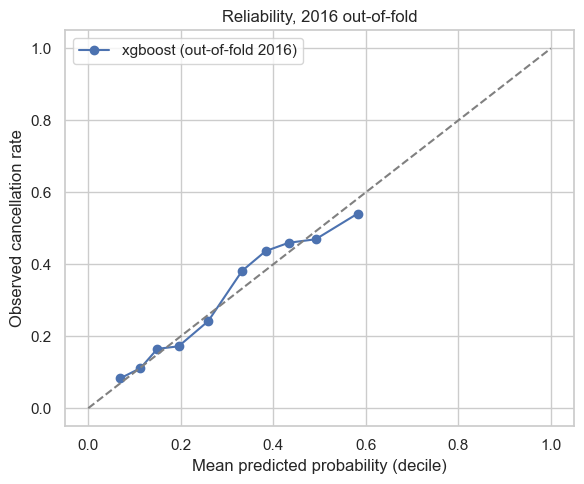

In [8]:
p_sel = OOF_SCORES[SELECTED]
m12 = OOF['fold'].isin(['fold_1', 'fold_2']).to_numpy(); m3 = OOF['fold'].eq('fold_3').to_numpy()
cal_rows = []
for method in ['none', 'sigmoid', 'isotonic']:
    cal = fm.fit_calibrator(method, p_sel[m12], y_oof[m12])
    p3 = fm.apply_calibrator(cal, p_sel[m3])
    cal_rows.append({'calibration': method, 'fold3_brier': brier_score_loss(y_oof[m3], p3),
                     'fold3_log_loss': log_loss(y_oof[m3], np.clip(p3, 1e-6, 1 - 1e-6)),
                     'fold3_mean_p': p3.mean(), 'fold3_cancel_rate': y_oof[m3].mean()})
CAL_TABLE = pd.DataFrame(cal_rows).set_index('calibration')
display(CAL_TABLE.round(4))
best_cal = CAL_TABLE['fold3_brier'].idxmin()
CALIBRATION = best_cal if CAL_TABLE.loc['none', 'fold3_brier'] - CAL_TABLE.loc[best_cal, 'fold3_brier'] > CONFIG['calibration_tolerance_brier'] else 'none'
print('Calibration chosen on pre-test evidence:', CALIBRATION)

fig, ax = plt.subplots(figsize=(6, 5))
dec = pd.qcut(pd.Series(p_sel).rank(method='first'), 10, labels=False)
rel = pd.DataFrame({'p': p_sel, 'y': y_oof, 'd': dec}).groupby('d').mean()
ax.plot(rel['p'], rel['y'], 'o-', label=f'{SELECTED} (out-of-fold 2016)'); ax.plot([0, 1], [0, 1], '--', color='grey')
ax.set(xlabel='Mean predicted probability (decile)', ylabel='Observed cancellation rate', title='Reliability, 2016 out-of-fold'); ax.legend()
plt.tight_layout(); plt.show()

## 6. Operating policy (F2)
**Why not a frozen probability threshold.** Probability levels move with season and drift, so a fixed cut-off produces a queue whose size the hotel cannot plan (v2: 20% → 66.7%). The operating rule is therefore **capacity-based**:

> At the **end of every booking week** (Sunday, the decision time), score the bookings created that week that are still eligible (decision table §2) and rank them. **high** = top 5% (phone call, rule I3), **medium** = next 15% (personalised reminders, I2), **low** = the rest (standard confirmation, I1). Slots per batch are **floor**(share × batch size): the shares are hard ceilings, so a batch below 20 bookings gets no high slot and a batch below 5 gets no slot at all. Ties are broken by a fixed hash of `booking_id`.

The weekly decision time is what makes the ranking feasible: a booking created on Monday cannot be ranked against bookings created later that week until the week has closed. The 5% / 20% shares are placeholders for the reservations team's real capacity (decision table §3); the table below shows the trade-off at 5 / 10 / 20 / 30% on the **2016 out-of-fold cohort** (retrospective batches) so the owner can pick. A probability cut-off equal to the 80th percentile of the 2016 out-of-fold scores is carried to test as a **diagnostic** only.

**KPI M1 check.** With a 20% queue, recall cannot exceed (20% × bookings) / cancellations of the same population: "Recall ≥ 70%" is impossible at 20% capacity and is replaced by Precision / Lift / Recall at k% (`docs/kpi_register.csv`).

In [9]:
def flag_top_share(p, batch, ids, share):
    """Top `share` of every batch with the capacity rounding of CONFIG (floor = hard ceiling)."""
    rk = fm.rank_in_batch(p, batch, ids)
    return rk['r'].to_numpy() < fm.capacity_slots(rk['n'], share, CONFIG['capacity_rounding'])

batch_oof, ids_oof = OOF['booking_week'].to_numpy(), OOF['booking_id'].to_numpy()
cap_rows = []
for share in [0.05, 0.10, 0.20, 0.30]:
    flag = flag_top_share(p_sel, batch_oof, ids_oof, share)
    cap_rows.append({'capacity_share': share, 'alerts': int(flag.sum()), 'precision': y_oof[flag].mean(),
                     'recall': y_oof[flag].sum() / y_oof.sum(), 'max_possible_recall': min(1, flag.sum() / y_oof.sum()),
                     'lift': y_oof[flag].mean() / y_oof.mean()})
display(pd.DataFrame(cap_rows).round(3))
print('Retrospective view: batches = booking weeks of the 2016 out-of-fold arrival cohort, not an operational queue.')
DIAGNOSTIC_CUTOFF = float(np.quantile(p_sel, 0.80))
print(f'Diagnostic fixed cut-off (80th percentile of 2016 OOF scores): {DIAGNOSTIC_CUTOFF:.4f}')

,capacity_share,alerts,precision,recall,max_possible_recall,lift
0,0.05,1046,0.560,0.088,0.158,1.830
1,0.10,2130,0.538,0.173,0.322,1.757
2,0.20,4294,0.507,0.329,0.648,1.656
3,0.30,6457,0.491,0.478,0.975,1.603


Retrospective view: batches = booking weeks of the 2016 out-of-fold arrival cohort, not an operational queue.
Diagnostic fixed cut-off (80th percentile of 2016 OOF scores): 0.4607


## 7. Final model, bundle and test evaluation (F2)
Refit the frozen configuration on all individual arrivals up to 2016-12-31 (label maturity asserted) and fit the group rule on the same cutoff. The bundle stores everything needed to score **both tracks**: pipeline (with the fold-safe top-agent list), calibrator, feature list, population rule, group rule, fit date and selection cutoff, policy, eligibility checks and library versions. `fm.score_bookings(bundle, frame, score_time)` dispatches each booking to the individual model or the group rule and refuses a score time on or before the fit date / selection cutoff. A smoke test reloads the bundle and must reproduce the predictions exactly. **Test 2017 is opened here** (once in this run; it remains a partially explored holdout).

In [10]:
fit_final = train_rows(ind, CONFIG['fit_date_final'])
final_pipe = fm.build_pipeline(SELECTED, NUM, CAT, SELECTED_PARAMS, seed=SEED, top_agents=CONFIG['top_agents'])
fm.fit_pipeline(final_pipe, fit_final, FEATURES, CONFIG['fit_date_final'], SELECTED_PARAMS.get('half_life_days', 0))
final_cal = fm.fit_calibrator(CALIBRATION, p_sel, y_oof)
# Group track (rule, not ML) on the same cutoff, so the hand-over bundle can score the whole hotel
grp_fit = train_rows(grp, CONFIG['fit_date_final'])
group_rule = fm.RateTableRule(['market_segment', 'deposit_type'], m=30).fit(grp_fit)
BUNDLE = {'model': final_pipe, 'calibrator': final_cal, 'calibration': CALIBRATION, 'features': FEATURES,
          'model_name': SELECTED, 'params': SELECTED_PARAMS, 'model_version': CONFIG['model_version'], 'run_id': RUN_ID,
          'fit_date': CONFIG['fit_date_final'], 'selection_cutoff': CONFIG['fit_date_final'],
          'population': 'individual (rule A, notebook 03)',
          'population_rule': {'rule': 'A', 'block_size': CONFIG['population_block_size'], 'definition': cfg['population_rule']},
          'group_rule': group_rule, 'group_rule_keys': ['market_segment', 'deposit_type'], 'group_fit_date': CONFIG['fit_date_final'],
          'feature_set': 'booking_time',
          'policy': {k: CONFIG[k] for k in ['tier_high_share', 'tier_medium_share', 'capacity_rounding', 'scoring_batch', 'decision_time']},
          'eligibility_checks': ['created_by_decision', 'arrival_after_decision', 'active_at_decision', 'not_complimentary',
                                 'consent_status (not in data: unknown)', 'open_action_check (not in data: unknown)'],
          'output_schema': 'hotel.risk_scores (sql/schema.sql)',
          'top_agents': final_pipe.named_steps['preprocess'].named_transformers_['agent'].named_steps['top'].top_agents_,
          'environment': ENV}
joblib.dump(BUNDLE, OUT / 'final_model_bundle.joblib')

test = ind[is_test(ind)].copy()
p_test = fm.score(BUNDLE, test)
loaded = fm.load_bundle(OUT / 'final_model_bundle.joblib')
assert np.array_equal(p_test, fm.score(loaded, test)), 'smoke test failed: reloaded bundle scores differently'
assert set(test['booking_id']).isdisjoint(fit_final['booking_id'])
# Two-track smoke test after reload: individual rows -> model, group rows -> rule; a score time before the fit date is refused
smoke = pd.concat([test.head(200), grp[is_test(grp)].head(200)])
sb = fm.score_bookings(loaded, smoke, '2017-03-05')
is_i = sb['population'].eq('individual')
assert (sb['population'] == smoke['population']).all()
assert np.allclose(sb.loc[is_i, 'p_cancel'], fm.score(BUNDLE, smoke[is_i]))
assert np.allclose(sb.loc[~is_i, 'p_cancel'], group_rule.predict(smoke[~is_i]))
try:
    fm.score_bookings(loaded, smoke, CONFIG['fit_date_final'])
    raise AssertionError('a score time on the fit date was accepted')
except ValueError:
    pass
test['p_cancel'] = p_test
y_test = test['is_canceled'].to_numpy()
tie_test = test['tie'].to_numpy()
print(f'Smoke tests passed. Fit rows {len(fit_final):,}; test rows {len(test):,}; top agents {BUNDLE["top_agents"]}')

# Rules and baselines refitted on the same fit rows for a fair comparison on test
TEST_SCORES = {
    'final_model': p_test,
    'rule_segment_x_leadband': fm.RateTableRule(['market_segment', 'lead_band']).fit(fit_final).predict(test),
    'rule_lead_time': test['lead_time'].to_numpy(dtype=float),
    'baseline_logistic': fm.fit_pipeline(fm.build_pipeline('baseline_logistic', ['lead_time'], ['market_segment']),
                                         fit_final, ['lead_time', 'market_segment'], CONFIG['fit_date_final']
                                         ).predict_proba(test[['lead_time', 'market_segment']])[:, 1],
}
const = np.full(len(test), fit_final['is_canceled'].mean())
TEST_METRICS = pd.DataFrame([{'scorer': n, **fm.metric_bundle(y_test, s, tie_breaker=tie_test),
                              'brier': brier_score_loss(y_test, s) if n != 'rule_lead_time' else np.nan}
                             for n, s in TEST_SCORES.items()] +
                            [{'scorer': 'constant (train rate)', 'brier': brier_score_loss(y_test, const), 'roc_auc': 0.5,
                              'pr_auc': y_test.mean()}]).set_index('scorer')
TEST_METRICS.insert(0, 'test_cancel_rate', y_test.mean())
print('Retrospective arrival-cohort evaluation (top-k = cohort ranking, k = ceil(share x n)):')
display(TEST_METRICS[['test_cancel_rate', 'roc_auc', 'pr_auc', 'brier', 'precision@5%', 'precision@10%', 'precision@20%', 'lift@20%', 'recall@20%']].round(4))

Smoke tests passed. Fit rows 32,277; test rows 20,399; top agents ['10', '11', '138', '14', '16', '22', '27', '28', '3', '6', '7', '8', '83', '85', '9']


Retrospective arrival-cohort evaluation (top-k = cohort ranking, k = ceil(share x n)):


,test_cancel_rate,roc_auc,pr_auc,brier,precision@5%,precision@10%,precision@20%,lift@20%,recall@20%
scorer,,,,,,,,,
final_model,0.3437,0.7356,0.5556,0.1918,0.6618,0.6069,0.5831,1.6963,0.3393
rule_segment_x_leadband,0.3437,0.6775,0.4678,0.2061,0.5412,0.5525,0.5076,1.4767,0.2954
rule_lead_time,0.3437,0.6282,0.4498,NaN,0.5863,0.5328,0.4676,1.3605,0.2721
baseline_logistic,0.3437,0.6759,0.4934,0.2085,0.6147,0.5583,0.5088,1.4802,0.2961
constant (train rate),0.3437,0.5000,0.3437,0.2296,NaN,NaN,NaN,NaN,NaN


### 7.1 Operational queue simulation (time contract of the hand-over)
This is the view that `risk_scores.csv`, the tiers, the action queue / schedule and the workload come from. Contract:
- **Decision time** = end of the booking week (Sunday). The batch = bookings **created in that week** (both populations, not only one arrival cohort).
- **Model availability**: only weeks closing after the model's fit date and selection cutoff (2016-12-31) are scored. Bookings created earlier (36% of the 2017 arrivals) would have been scored by an earlier model; they are not in this simulation and are counted below.
- **Eligibility at the decision time** (decision table §2): created, not cancelled (`reservation_status_date` used only for this check), arrival still ahead, not complimentary (Complementary with ADR 0). Consent / opt-out and open actions are **not in the data**: the columns say `unknown`, never "passed".
- `days_to_arrival` is measured from the decision time. Tiers are computed once, here, and every later table joins this canonical table.

Because every eligible booking of a week closing on or after 2017-01-01 arrives after that date, the queue's individual rows are all 2017 test arrivals; the extract has no arrivals after 2017-08-31, so the last summer weeks miss their far-ahead bookings (data truncation, not a modelling choice). The model's p for a booking is the same as in the retrospective evaluation (same model, same snapshot inputs); what changes is **who is in the batch and when**.

In [11]:
cand = df.assign(decision_at=fm.week_end(df['booking_date']))
cand = cand[cand['decision_at'].gt(pd.Timestamp(BUNDLE['fit_date']))]       # weeks that close after the model existed
SCORED = pd.concat([fm.score_bookings(BUNDLE, part, t) for t, part in cand.groupby('decision_at')])
SCORED = SCORED.join(cand[['booking_date', 'arrival_date', 'booking_week', 'arrival_month', 'is_canceled', 'gross_value', 'market_segment',
                           'customer_type', 'lead_time', 'total_nights', 'tie']])
before_fit = lambda f: f[is_test(f) & fm.week_end(f['booking_date']).le(pd.Timestamp(BUNDLE['fit_date']))]
CONTRACT = (SCORED.assign(status=SCORED['ineligible_reason'].replace('', 'eligible (known checks)'))
            .groupby(['status', 'population']).size().unstack(fill_value=0))
CONTRACT.loc['not scored: 2017 arrival created in a week closing on/before the fit date'] = pd.Series(
    {'group_block': len(before_fit(grp)), 'individual': len(before_fit(ind))})
CONTRACT['consent / open action'] = 'unknown (not in data)'
display(CONTRACT)

QUEUE = SCORED[SCORED['eligible_known_checks']].copy()
assert QUEUE['score_time'].gt(pd.Timestamp(BUNDLE['fit_date'])).all() and QUEUE['score_time'].ge(QUEUE['booking_date']).all()
assert QUEUE['days_to_arrival'].ge(1).all()
qi = QUEUE['population'].eq('individual')
assert set(QUEUE.loc[qi, 'booking_id']) <= set(test['booking_id']), 'operational individual rows must be 2017 arrivals'
assert np.allclose(QUEUE.loc[qi, 'p_cancel'], test.set_index('booking_id').loc[QUEUE.loc[qi, 'booking_id'], 'p_cancel'])

QI = QUEUE[qi].copy()
QI['risk_tier'] = fm.assign_tier(QI['p_cancel'], QI['booking_week'], CONFIG['tier_high_share'], CONFIG['tier_medium_share'],
                                 ids=QI['booking_id'], rounding=CONFIG['capacity_rounding'])
QI[['rule', 'owner', 'approval']] = pd.DataFrame([fm.plan_rule(t, d) for t, d in zip(QI['risk_tier'], QI['days_to_arrival'])], index=QI.index)
QG = QUEUE[~qi].copy()
QG = QG.assign(risk_tier=None, rule='G2', owner='Revenue manager', approval='required')
SCORES = pd.concat([QI.assign(track='individual model'), QG.assign(track='group rule')])          # canonical score / tier table
SCORES['run_id'] = RUN_ID
SCORES['expected_revenue_at_risk'] = SCORES['p_cancel'] * SCORES['gross_value']
assert not SCORES.duplicated(['booking_id', 'score_time']).any()

# Weekly policy on the operational queue: model vs the segment x lead-band rule ranked in the SAME batches
y_q = QI['is_canceled'].to_numpy()
rule_q = fm.RateTableRule(['market_segment', 'lead_band']).fit(fit_final).predict(QI)
rule_tier = fm.assign_tier(rule_q, QI['booking_week'], CONFIG['tier_high_share'], CONFIG['tier_medium_share'],
                           ids=QI['booking_id'], rounding=CONFIG['capacity_rounding'])
flag_m, high_m = QI['risk_tier'].ne('low').to_numpy(), QI['risk_tier'].eq('high').to_numpy()
flag_r, high_r = rule_tier != 'low', rule_tier == 'high'
retro_tier = fm.assign_tier(p_test, test['booking_week'], CONFIG['tier_high_share'], CONFIG['tier_medium_share'],
                            ids=test['booking_id'], rounding=CONFIG['capacity_rounding'])
def pol_row(scope, name, flag, y):
    flag = np.asarray(flag, bool)
    return {'population': scope, 'policy': name, 'base_bookings': len(y), 'alerts': int(flag.sum()), 'alert_share': flag.mean(),
            'cancellations_in_base': int(y.sum()), 'TP': int(y[flag].sum()), 'precision': y[flag].mean(),
            'recall': y[flag].sum() / y.sum(), 'recall_ceiling': min(1, flag.sum() / y.sum()), 'lift': y[flag].mean() / y.mean()}
QQ, COH = 'operational weekly queue 2017', 'arrival cohort 2017 (retrospective)'
POLICY_TEST = pd.DataFrame([
    pol_row(QQ, 'model: high + medium (top 20% per weekly batch)', flag_m, y_q),
    pol_row(QQ, 'model: high (top 5% per weekly batch)', high_m, y_q),
    pol_row(QQ, 'rule segment x lead band: top 20% per weekly batch', flag_r, y_q),
    pol_row(QQ, 'rule segment x lead band: top 5% per weekly batch', high_r, y_q),
    pol_row(QQ, f'diagnostic fixed cut-off p >= {DIAGNOSTIC_CUTOFF:.3f}', QI['p_cancel'].to_numpy() >= DIAGNOSTIC_CUTOFF, y_q),
    pol_row(COH, 'model: top 20% per booking week of the arrival cohort (v3 definition, not operational)', retro_tier != 'low', y_test),
]).set_index('policy')
display(POLICY_TEST.round(3))

PB = fm.policy_bootstrap(y_q, {'model_20': flag_m, 'rule_20': flag_r, 'model_5': high_m, 'rule_5': high_r},
                         QI['booking_week'].to_numpy(), n_boot=CONFIG['bootstrap_draws'], seed=SEED)
pdiff = []
for share in ['20', '5']:
    for metric in ['precision', 'tp']:
        d = PB[f'model_{share}'][metric] - PB[f'rule_{share}'][metric]
        point_m = POLICY_TEST.iloc[0 if share == '20' else 1]; point_r = POLICY_TEST.iloc[2 if share == '20' else 3]
        point = point_m['precision'] - point_r['precision'] if metric == 'precision' else point_m['TP'] - point_r['TP']
        lo, hi = d.quantile([0.025, 0.975])
        pdiff.append({'policy': f'top {share}% per weekly batch (operational queue)', 'metric': metric, 'model_minus_rule': point,
                      'ci_low': lo, 'ci_high': hi, 'significant': bool(lo > 0 or hi < 0)})
POLICY_DIFF = pd.DataFrame(pdiff)
display(POLICY_DIFF.round(4))
sizes = QI.groupby('booking_week').size()
print(f'Queue: {len(QI):,} eligible individual bookings in {len(sizes)} weekly batches (median {sizes.median():.0f}, min {sizes.min()}); '
      f'{len(QG):,} group bookings to the capacity track. Recall ceiling at 20%: {flag_m.sum() / y_q.sum():.3f}.')

population,group_block,individual,consent / open action
status,,,
already cancelled,1232,1619,unknown (not in data)
arrived,61,1797,unknown (not in data)
complimentary (adr 0),0,56,unknown (not in data)
eligible (known checks),1054,12102,unknown (not in data)
not scored: 2017 arrival created in a week closing on/before the fit date,4650,4857,unknown (not in data)


,population,base_bookings,alerts,alert_share,cancellations_in_base,TP,precision,recall,recall_ceiling,lift
policy,,,,,,,,,,
model: high + medium (top 20% per weekly batch),operational weekly queue 2017,12102,2408,0.199,2910,989,0.411,0.340,0.827,1.708
model: high (top 5% per weekly batch),operational weekly queue 2017,12102,587,0.049,2910,271,0.462,0.093,0.202,1.920
rule segment x lead band: top 20% per weekly batch,operational weekly queue 2017,12102,2408,0.199,2910,850,0.353,0.292,0.827,1.468
rule segment x lead band: top 5% per weekly batch,operational weekly queue 2017,12102,587,0.049,2910,229,0.390,0.079,0.202,1.622
diagnostic fixed cut-off p >= 0.461,operational weekly queue 2017,12102,2197,0.182,2910,939,0.427,0.323,0.755,1.777
"model: top 20% per booking week of the arrival cohort (v3 definition, not operational)",arrival cohort 2017 (retrospective),20399,4044,0.198,7012,2192,0.542,0.313,0.577,1.577


,policy,metric,model_minus_rule,ci_low,ci_high,significant
0,top 20% per weekly batch (operational queue),precision,0.0577,0.0214,0.0875,True
1,top 20% per weekly batch (operational queue),tp,139.0000,48.4750,232.0000,True
2,top 5% per weekly batch (operational queue),precision,0.0716,0.0074,0.1309,True
3,top 5% per weekly batch (operational queue),tp,42.0000,4.0000,80.5250,True


Queue: 12,102 eligible individual bookings in 35 weekly batches (median 319, min 10); 1,054 group bookings to the capacity track. Recall ceiling at 20%: 0.827.


### 7.1b Precision, recall and F1 at every operating point
Precision / recall / F1 depend on how many bookings are flagged, so they are reported per operating point and per **population** (retrospective arrival cohort vs operational weekly queue — never mix the two in one comparison). **F1 is not the selection criterion.** It does not always rise when more bookings are flagged (it typically rises and then falls, see the sweep below), and it ignores the contact capacity and the cost of a contact, which are what bind here; Precision@k and Lift@k at the planned capacity are the headline.

In [12]:
order_model = np.lexsort((tie_test, -p_test))
order_rule = np.lexsort((tie_test, -TEST_SCORES['rule_segment_x_leadband']))
def prf(name, scope, flag, y):
    flag, y = np.asarray(flag, bool), np.asarray(y)
    tp, n, pos = int((flag & (y == 1)).sum()), int(flag.sum()), int(y.sum())
    precision, recall = tp / n, tp / pos
    return {'operating_point': name, 'population': scope, 'base_bookings': len(y), 'flag_share': n / len(y), 'flagged': n,
            'TP': tp, 'FP': n - tp, 'FN': pos - tp, 'TN': len(y) - n - (pos - tp), 'precision': precision, 'recall': recall,
            'recall_ceiling': min(1.0, n / pos), 'f1': 2 * precision * recall / (precision + recall), 'lift': precision / y.mean()}
def top(order, share):
    flag = np.zeros(len(test), bool); flag[order[:int(np.ceil(share * len(test)))]] = True; return flag
COHORT_TOP20 = top(order_model, 0.20)
test['cohort_top20'] = COHORT_TOP20
PRF = [prf(f'model top {int(k * 100)}% (cohort)', COH, top(order_model, k), y_test) for k in [0.05, 0.10, 0.20, 0.30, 0.40, 0.50]]
PRF += [prf(f'model fixed cut-off p >= {DIAGNOSTIC_CUTOFF:.3f} (from 2016)', COH, p_test >= DIAGNOSTIC_CUTOFF, y_test),
        prf('model p >= 0.5', COH, p_test >= 0.5, y_test),
        prf('rule segment x lead band top 20% (cohort)', COH, top(order_rule, 0.20), y_test),
        prf('model at v1 flag rate (59.6%)', COH, top(order_model, 0.596), y_test),
        prf('model at v2 flag rate (66.7%)', COH, top(order_model, 0.667), y_test),
        prf('model tier high (top 5% per weekly batch)', QQ, high_m, y_q),
        prf('model tier high+medium (top 20% per weekly batch)', QQ, flag_m, y_q),
        prf('rule segment x lead band, top 20% per weekly batch', QQ, flag_r, y_q)]
PRF = pd.DataFrame(PRF).set_index('operating_point')
display(PRF.round(3))
sweep = pd.DataFrame([prf(f'{k:.2f}', COH, top(order_model, k), y_test) for k in np.arange(0.05, 1.0001, 0.05)])
best_f1 = sweep.loc[sweep['f1'].idxmax()]
print(f"F1 sweep on the cohort: max F1 {best_f1['f1']:.3f} at {best_f1['flag_share']:.0%} flagged; F1 at 100% flagged = {sweep['f1'].iloc[-1]:.3f}.")
print('Archived results at their own operating points (test 2017): v1 precision 0.481 / recall 0.834 / F1 0.610 at 59.6% flagged; '
      'v2 precision 0.452 / recall 0.877 / F1 0.597 at 66.7% flagged.')

,population,base_bookings,flag_share,flagged,TP,FP,FN,TN,precision,recall,recall_ceiling,f1,lift
operating_point,,,,,,,,,,,,,
model top 5% (cohort),arrival cohort 2017 (retrospective),20399,0.050,1020,675,345,6337,13042,0.662,0.096,0.145,0.168,1.925
model top 10% (cohort),arrival cohort 2017 (retrospective),20399,0.100,2040,1238,802,5774,12585,0.607,0.177,0.291,0.274,1.765
model top 20% (cohort),arrival cohort 2017 (retrospective),20399,0.200,4080,2379,1701,4633,11686,0.583,0.339,0.582,0.429,1.696
model top 30% (cohort),arrival cohort 2017 (retrospective),20399,0.300,6120,3441,2679,3571,10708,0.562,0.491,0.873,0.524,1.636
model top 40% (cohort),arrival cohort 2017 (retrospective),20399,0.400,8160,4368,3792,2644,9595,0.535,0.623,1.000,0.576,1.557
model top 50% (cohort),arrival cohort 2017 (retrospective),20399,0.500,10200,5199,5001,1813,8386,0.510,0.741,1.000,0.604,1.483
model fixed cut-off p >= 0.461 (from 2016),arrival cohort 2017 (retrospective),20399,0.227,4631,2686,1945,4326,11442,0.580,0.383,0.660,0.461,1.687
model p >= 0.5,arrival cohort 2017 (retrospective),20399,0.122,2479,1480,999,5532,12388,0.597,0.211,0.354,0.312,1.737
rule segment x lead band top 20% (cohort),arrival cohort 2017 (retrospective),20399,0.200,4080,2071,2009,4941,11378,0.508,0.295,0.582,0.373,1.477


F1 sweep on the cohort: max F1 0.614 at 60% flagged; F1 at 100% flagged = 0.512.
Archived results at their own operating points (test 2017): v1 precision 0.481 / recall 0.834 / F1 0.610 at 59.6% flagged; v2 precision 0.452 / recall 0.877 / F1 0.597 at 66.7% flagged.


### 7.1c Workload (for G1 staffing)
**Planning estimate (2016 booking dates).** 2016 is the only complete calendar year of booking dates in the extract. Multiplying new individual bookings per day by the 5% / 15% shares gives an upper planning figure: it ignores the eligibility filter and the floor rounding, so the real queue is a little smaller.

**Operational queue 2017 (by decision month).** The work the simulated queue actually creates, counted at the decision time: I3 phone calls, I5 buffer counts, I2 reminder sequences. Summer decision months miss bookings for arrivals after 31/08/2017 (end of the extract), so their counts are too low.

In [13]:
staff = ind[ind['booking_date'].dt.year.eq(2016)].assign(booking_month=lambda d: d['booking_date'].dt.to_period('M'))
STAFFING = staff.groupby('booking_month').agg(new_individual_bookings=('booking_id', 'size'))
STAFFING['days'] = STAFFING.index.days_in_month
STAFFING['new_bookings_per_day'] = (STAFFING['new_individual_bookings'] / STAFFING['days']).round(1)
STAFFING['phone_calls_per_day_I3 (5%)'] = (STAFFING['new_bookings_per_day'] * CONFIG['tier_high_share']).round(1)
STAFFING['reminder_sequences_per_day_I2 (15%)'] = (STAFFING['new_bookings_per_day'] * (CONFIG['tier_medium_share'] - CONFIG['tier_high_share'])).round(1)
STAFFING.index = STAFFING.index.astype(str)
display(STAFFING)
print(f"2016 planning estimate: {STAFFING['new_bookings_per_day'].mean():.1f} new individual bookings/day -> at most "
      f"{STAFFING['phone_calls_per_day_I3 (5%)'].mean():.1f} calls/day and {STAFFING['reminder_sequences_per_day_I2 (15%)'].mean():.1f} reminder sequences/day.")

w = QI.assign(decision_month=QI['score_time'].dt.to_period('M'),
              flagged=QI['risk_tier'].ne('low'), flagged_cancel=QI['risk_tier'].ne('low') & QI['is_canceled'].eq(1))
WORKLOAD = w.groupby('decision_month').agg(weekly_batches=('booking_week', 'nunique'), queued=('booking_id', 'size'),
                                           high=('risk_tier', lambda s: int(s.eq('high').sum())),
                                           medium=('risk_tier', lambda s: int(s.eq('medium').sum())),
                                           phone_calls_I3=('rule', lambda s: int(s.eq('I3').sum())),
                                           buffer_I5=('rule', lambda s: int(s.eq('I5').sum())),
                                           reminder_sequences_I2=('rule', lambda s: int(s.eq('I2').sum())),
                                           median_days_to_arrival=('days_to_arrival', 'median'),
                                           cancellations_among_flagged=('flagged_cancel', 'sum'))
WORKLOAD['phone_calls_per_day'] = (WORKLOAD['phone_calls_I3'] / WORKLOAD.index.days_in_month).round(1)
WORKLOAD['alert_share'] = ((WORKLOAD['high'] + WORKLOAD['medium']) / WORKLOAD['queued']).round(3)
WORKLOAD['precision_among_flagged'] = (WORKLOAD['cancellations_among_flagged'] / (WORKLOAD['high'] + WORKLOAD['medium'])).round(3)
WORKLOAD.index = WORKLOAD.index.astype(str)
display(WORKLOAD)

,new_individual_bookings,days,new_bookings_per_day,phone_calls_per_day_I3 (5%),reminder_sequences_per_day_I2 (15%)
booking_month,,,,,
2016-01,3843,31,124.0,6.2,18.6
2016-02,3706,29,127.8,6.4,19.2
2016-03,2810,31,90.6,4.5,13.6
2016-04,2421,30,80.7,4.0,12.1
2016-05,2129,31,68.7,3.4,10.3
2016-06,1704,30,56.8,2.8,8.5
2016-07,1956,31,63.1,3.2,9.5
2016-08,2211,31,71.3,3.6,10.7
2016-09,2491,30,83.0,4.2,12.5


2016 planning estimate: 82.3 new individual bookings/day -> at most 4.1 calls/day and 12.3 reminder sequences/day.


,weekly_batches,queued,high,medium,phone_calls_I3,buffer_I5,reminder_sequences_I2,median_days_to_arrival,cancellations_among_flagged,phone_calls_per_day,alert_share,precision_among_flagged
decision_month,,,,,,,,,,,,
2017-01,5,3671,182,550,178,4,548,82.0,342,5.7,0.199,0.467
2017-02,4,2633,130,396,129,1,395,80.0,210,4.6,0.200,0.399
2017-03,4,1475,71,222,68,3,222,77.0,121,2.2,0.199,0.413
2017-04,5,1665,81,251,78,3,250,41.0,135,2.6,0.199,0.407
2017-05,4,1270,62,191,62,0,191,31.0,89,2.0,0.199,0.352
2017-06,4,608,28,92,28,0,92,23.5,45,0.9,0.197,0.375
2017-07,5,603,27,91,27,0,85,15.0,41,0.9,0.196,0.347
2017-08,4,177,6,28,6,0,20,7.0,6,0.2,0.192,0.176


### 7.2 Is the model better than the simple rules? (paired block bootstrap, cohort top-k)
Arrival weeks are resampled whole (bookings of the same week are correlated); the same draw is applied to every scorer, so differences are paired. The model only "adds value" where the 95% CI of the difference excludes 0. **These intervals apply to the cohort-level top-k ranking** (retrospective). The weekly operational policy has its own paired bootstrap (resampling whole weekly batches) in §7.1 (`policy_queue_diff.csv`); the two must not be mixed.

In [14]:
BOOT = fm.block_bootstrap(y_test, TEST_SCORES, test['arrival_week'].to_numpy(), n_boot=CONFIG['bootstrap_draws'], seed=SEED)
point = {n: fm.metric_bundle(y_test, s, tie_breaker=tie_test) for n, s in TEST_SCORES.items()}
diff_rows = []
for other in ['rule_segment_x_leadband', 'rule_lead_time', 'baseline_logistic']:
    for metric in ['roc_auc', 'pr_auc', 'precision@5%', 'precision@10%', 'precision@20%', 'lift@20%']:
        d = BOOT['final_model'][metric] - BOOT[other][metric]
        lo, hi = d.quantile([0.025, 0.975])
        diff_rows.append({'model_minus': other, 'metric': metric, 'diff': point['final_model'][metric] - point[other][metric],
                          'ci_low': lo, 'ci_high': hi, 'significant': bool(lo > 0 or hi < 0)})
DIFFS = pd.DataFrame(diff_rows)
display(DIFFS.round(4))
k20 = int(np.ceil(0.2 * len(test)))
caught = {n: int(round(point[n]['precision@20%'] * k20)) for n in TEST_SCORES}
print(f'Cohort top 20% ({k20:,} bookings, retrospective): cancellations reached', caught)
print(f"Model vs segment x lead-band rule (cohort top 20%): +{caught['final_model'] - caught['rule_segment_x_leadband']} cancellations detected (not avoided).")
print(f"Weekly operational queue (same batches, top 20%): model {int(POLICY_TEST.iloc[0]['TP'])} vs rule {int(POLICY_TEST.iloc[2]['TP'])} -> "
      f"+{int(POLICY_TEST.iloc[0]['TP'] - POLICY_TEST.iloc[2]['TP'])} (CI in policy_queue_diff.csv).")

,model_minus,metric,diff,ci_low,ci_high,significant
0,rule_segment_x_leadband,roc_auc,0.0581,0.0508,0.0667,True
1,rule_segment_x_leadband,pr_auc,0.0878,0.0777,0.1005,True
2,rule_segment_x_leadband,precision@5%,0.1206,0.0813,0.1554,True
3,rule_segment_x_leadband,precision@10%,0.0544,0.0261,0.0838,True
4,rule_segment_x_leadband,precision@20%,0.0755,0.0537,0.0995,True
5,rule_segment_x_leadband,lift@20%,0.2196,0.1514,0.2901,True
6,rule_lead_time,roc_auc,0.1075,0.0951,0.1203,True
7,rule_lead_time,pr_auc,0.1058,0.0864,0.1261,True
8,rule_lead_time,precision@5%,0.0755,0.0105,0.1384,True
9,rule_lead_time,precision@10%,0.0740,0.0279,0.1157,True


Cohort top 20% (4,080 bookings, retrospective): cancellations reached {'final_model': 2379, 'rule_segment_x_leadband': 2071, 'rule_lead_time': 1908, 'baseline_logistic': 2076}
Model vs segment x lead-band rule (cohort top 20%): +308 cancellations detected (not avoided).
Weekly operational queue (same batches, top 20%): model 989 vs rule 850 -> +139 (CI in policy_queue_diff.csv).


### 7.3 Ranking quality and calibration on test: decile table and monthly stability

,bookings,mean_p,cancel_rate,cancellations,cancelled_gross_eur,gap_observed_minus_p,cum_share_cancellations,cum_share_cancelled_gross
risk_decile,,,,,,,,
1,2040,0.569,0.607,1238,787797.66,0.038,0.177,0.242
2,2040,0.488,0.559,1141,530464.13,0.071,0.339,0.405
3,2040,0.454,0.521,1062,497978.52,0.066,0.491,0.558
4,2040,0.428,0.454,927,416285.85,0.027,0.623,0.685
5,2040,0.397,0.407,831,351274.29,0.010,0.741,0.793
6,2040,0.327,0.349,712,304331.64,0.022,0.843,0.887
7,2040,0.217,0.183,373,165905.29,-0.035,0.896,0.938
8,2040,0.174,0.151,308,97235.79,-0.023,0.940,0.967
9,2040,0.138,0.134,274,78880.27,-0.004,0.979,0.992


Largest decile gap |observed - mean p|: 0.071 (decile 2). Raw probabilities were kept because they had the best pre-test Brier; that does not make them exact in every decile.


,bookings,cancel_rate,mean_p,roc_auc,share_in_cohort_top20,precision_cohort_top20,lift_cohort_top20
arrival_month,,,,,,,
2017-01,1648.0,0.348,0.324,0.797,0.223,0.655,1.884
2017-02,1949.0,0.312,0.310,0.785,0.201,0.635,2.036
2017-03,2482.0,0.293,0.310,0.738,0.179,0.525,1.792
2017-04,2730.0,0.383,0.353,0.738,0.248,0.615,1.605
2017-05,3094.0,0.355,0.330,0.710,0.207,0.563,1.587
2017-06,2756.0,0.329,0.315,0.713,0.150,0.552,1.679
2017-07,2967.0,0.344,0.330,0.721,0.170,0.562,1.630
2017-08,2773.0,0.372,0.339,0.712,0.231,0.573,1.541


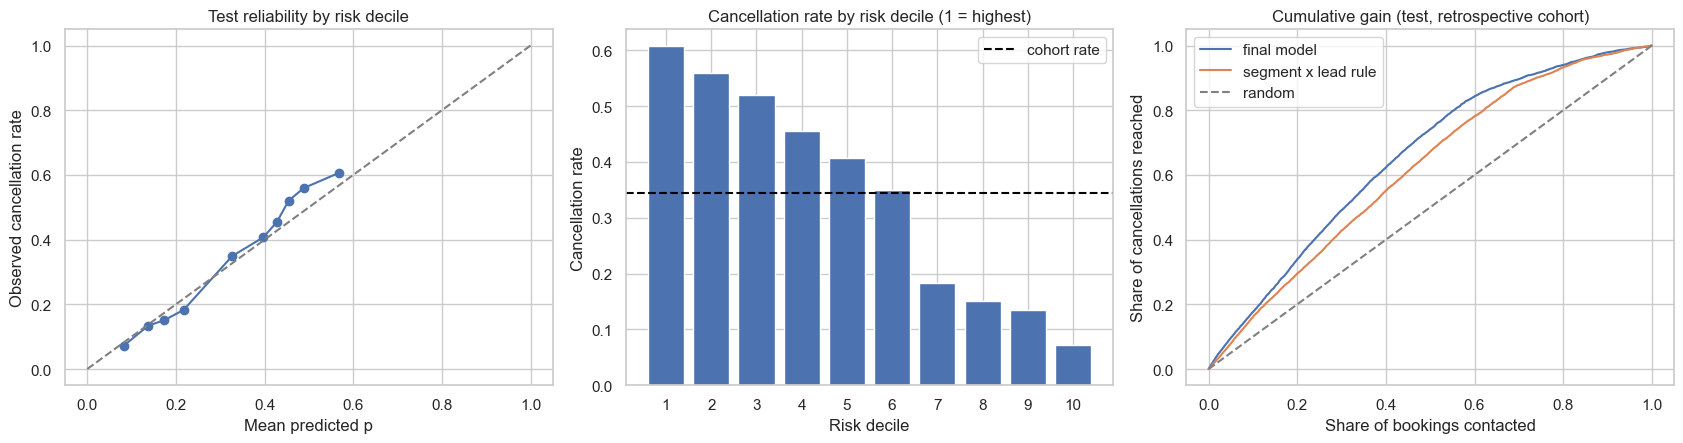

In [15]:
test['risk_decile'] = (fm.rank_share(test['p_cancel'], np.zeros(len(test)), ids=test['booking_id']) * 10).astype(int) + 1
test['lost_gross'] = test['gross_value'] * test['is_canceled']
DECILES = test.groupby('risk_decile').agg(bookings=('p_cancel', 'size'), mean_p=('p_cancel', 'mean'),
                                         cancel_rate=('is_canceled', 'mean'), cancellations=('is_canceled', 'sum'),
                                         cancelled_gross_eur=('lost_gross', 'sum'))
DECILES['gap_observed_minus_p'] = DECILES['cancel_rate'] - DECILES['mean_p']
DECILES['cum_share_cancellations'] = DECILES['cancellations'].cumsum() / DECILES['cancellations'].sum()
DECILES['cum_share_cancelled_gross'] = DECILES['cancelled_gross_eur'].cumsum() / DECILES['cancelled_gross_eur'].sum()
display(DECILES.round(3))
print(f"Largest decile gap |observed - mean p|: {DECILES['gap_observed_minus_p'].abs().max():.3f} "
      f"(decile {DECILES['gap_observed_minus_p'].abs().idxmax()}). Raw probabilities were kept because they had the best "
      "pre-test Brier; that does not make them exact in every decile.")

MONTHLY = test.groupby('arrival_month').apply(lambda g: pd.Series({
    'bookings': len(g), 'cancel_rate': g['is_canceled'].mean(), 'mean_p': g['p_cancel'].mean(),
    'roc_auc': roc_auc_score(g['is_canceled'], g['p_cancel']),
    'share_in_cohort_top20': g['cohort_top20'].mean(),
    'precision_cohort_top20': g.loc[g['cohort_top20'], 'is_canceled'].mean(),
    'lift_cohort_top20': g.loc[g['cohort_top20'], 'is_canceled'].mean() / g['is_canceled'].mean()}), include_groups=False)
display(MONTHLY.round(3))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
axes[0].plot(DECILES['mean_p'], DECILES['cancel_rate'], 'o-'); axes[0].plot([0, 1], [0, 1], '--', color='grey')
axes[0].set(title='Test reliability by risk decile', xlabel='Mean predicted p', ylabel='Observed cancellation rate')
axes[1].bar(DECILES.index.astype(str), DECILES['cancel_rate']); axes[1].axhline(y_test.mean(), color='black', ls='--', label='cohort rate')
axes[1].set(title='Cancellation rate by risk decile (1 = highest)', xlabel='Risk decile', ylabel='Cancellation rate'); axes[1].legend()
for name, s in [('final model', p_test), ('segment x lead rule', TEST_SCORES['rule_segment_x_leadband'])]:
    o = np.lexsort((tie_test, -s)); axes[2].plot(np.arange(1, len(o) + 1) / len(o), np.cumsum(y_test[o]) / y_test.sum(), label=name)
axes[2].plot([0, 1], [0, 1], '--', color='grey', label='random')
axes[2].set(title='Cumulative gain (test, retrospective cohort)', xlabel='Share of bookings contacted', ylabel='Share of cancellations reached'); axes[2].legend()
plt.tight_layout(); plt.show()

### 7.4 Subgroups (retrospective cohort; precision hidden below 30 alerts)
Alerts = bookings in the cohort top 20%. `lead_band` is the lead time **at booking** (0–7 days = booked close to arrival); it is not the notice period of a cancellation, so this table says nothing about "last-minute cancellations" of bookings made long before.

In [16]:
def subgroup(col):
    rows = []
    for g, part in test.groupby(col, observed=True):
        if len(part) < 100 or part['is_canceled'].nunique() < 2:
            continue
        flag = part['cohort_top20']
        rows.append({'segment_type': col, 'segment': g, 'bookings': len(part), 'cancel_rate': part['is_canceled'].mean(),
                     'roc_auc': roc_auc_score(part['is_canceled'], part['p_cancel']), 'alerts_cohort_top20': int(flag.sum()),
                     'precision': part.loc[flag, 'is_canceled'].mean() if flag.sum() >= CONFIG['min_alerts_for_precision'] else np.nan})
    return pd.DataFrame(rows)
test['lead_band'] = fm.lead_band(test['lead_time'])
SUBGROUPS = pd.concat([subgroup('market_segment'), subgroup('lead_band'), subgroup('customer_type')], ignore_index=True)
display(SUBGROUPS.round(3))

,segment_type,segment,bookings,cancel_rate,roc_auc,alerts_cohort_top20,precision
0,market_segment,Aviation,106,0.208,0.405,6,NaN
1,market_segment,Complementary,141,0.113,0.432,0,NaN
2,market_segment,Corporate,550,0.089,0.641,1,NaN
3,market_segment,Direct,2343,0.161,0.619,13,NaN
4,market_segment,Offline TA/TO,1868,0.166,0.601,1,NaN
5,market_segment,Online TA,15391,0.405,0.699,4059,0.584
6,lead_band,0-7d,2705,0.093,0.603,9,NaN
7,lead_band,180d+,3051,0.493,0.697,1338,0.646
8,lead_band,31-90d,5392,0.366,0.676,1145,0.528
9,lead_band,8-30d,3720,0.306,0.695,235,0.626


## 8. Robustness (F1 design §4–5)
Every row states its **population** and **time contract**. Rows A–3b reuse the frozen booking-time configuration, selected with the 2016-12-31 cutoff (= their fit date); no re-tuning on test.
1. **Booking-date-filtered retrospective view, population A**: only test bookings created after the 2016-12-31 fit date. This filters dates only: population A still uses `dup_group_size`, a block-size count from the near-arrival snapshot, so it is **not** a strict booking-time experiment.
2. **Duplicates**: retrain and evaluate without `is_duplicate == 1`.
3. **Population rule B**: `group_block` = Groups or Non Refund only (no block-size proxy); the extra rows join `individual`, retrain and evaluate.
3b. **Rule B + booked after the fit date (combined)**: no block-size proxy in the population split **and** booking date after the fit date — the closest available approximation of a booking-time experiment. Feature values are still snapshot values; rule B cannot recreate PMS history that the extract does not contain.
4. **`pre_arrival` H = 14 / 30 (strict)**: score date arrival − H; only bookings created by then and still active are eligible (training rows too); fit date = 2017-01-01 − H − 1 day. Each branch **selects its own configuration and calibration** on its three pre-arrival folds (F1 design §3) using only validation labels known by the branch cutoff: fold-3 rows whose label becomes known later are dropped from the selection evidence. Compared with and without `pre_arrival_extra` — special requests **and** waiting-list fields together, so the effect of special requests alone is not isolated; the +extras model reuses the configuration selected on the base inputs.
5. **Leakage illustration**: the same extra inputs **without** the eligibility filter (not valid).

The timing table counts **all** 2017 cancellations / no-shows whose outcome comes after the mark (Canceled: `reservation_status_date`; No-Show: arrival date), split into bookings eligible at the mark and bookings created after it.

In [17]:
def fit_predict(model_name, params, train_frame, eval_frame, features, num, fit_date):
    pipe = fm.build_pipeline(model_name, num, CAT, params, seed=SEED, top_agents=CONFIG['top_agents'])
    fm.fit_pipeline(pipe, train_frame, features, fit_date, params.get('half_life_days', 0))
    return pipe.predict_proba(eval_frame[features])[:, 1]

def fit_score(train_frame, eval_frame, features=FEATURES, num=NUM, fit_date=CONFIG['fit_date_final']):
    """Frozen booking-time configuration and calibrator (selection cutoff 2016-12-31)."""
    return fm.apply_calibrator(final_cal, fit_predict(SELECTED, SELECTED_PARAMS, train_frame, eval_frame, features, num, fit_date))

def row(view, frame, p, population, contract, note=''):
    y = frame['is_canceled'].to_numpy()
    return {'view': view, 'population': population, 'time_contract': contract, 'bookings': len(frame), 'cancel_rate': y.mean(),
            'roc_auc': roc_auc_score(y, p), 'pr_auc': average_precision_score(y, p),
            'lift@20%': fm.topk_stats(y, p, 0.2, frame['tie'].to_numpy())['lift'], 'brier': brier_score_loss(y, p), 'note': note}

FIT = CONFIG['fit_date_final']
POP_A = 'individual, rule A (block size from the snapshot)'
POP_B = 'individual, rule B (Groups / Non Refund only)'
RETRO = 'retrospective arrival cohort (exception to the strict rule)'
BDATE = 'booking date after the fit date (date filter only)'
ROBUST = [row('A. headline: all individual test 2017', test, p_test, POP_A, RETRO)]
bdate = test['booking_date'].gt(FIT).to_numpy()
ROBUST.append(row('1. booking-date-filtered retrospective view, population A', test[bdate], p_test[bdate], POP_A, BDATE,
                  f'{(~bdate).sum():,} test bookings created on/before the fit date excluded; not a strict booking-time test'))
nd_tr, nd_te = fit_final[fit_final['is_duplicate'].eq(0)], test[test['is_duplicate'].eq(0)]
ROBUST.append(row('2. no duplicates (retrained)', nd_te, fit_score(nd_tr, nd_te), POP_A + ', is_duplicate == 0', RETRO))

ind_b = df[fm.assign_population(df, 'B') == 'individual']
te_b = ind_b[is_test(ind_b)]
p_b = fit_score(train_rows(ind_b, FIT), te_b)
ROBUST.append(row('3. population rule B (retrained)', te_b, p_b, POP_B, RETRO, f'{len(ind_b) - len(ind):,} extra bookings move to individual'))
bdate_b = te_b['booking_date'].gt(FIT).to_numpy()
moved = int((te_b['population'].eq('group_block').to_numpy() & bdate_b).sum())
ROBUST.append(row('3b. rule B + booked after the fit date (combined)', te_b[bdate_b], p_b[bdate_b], POP_B,
                  BDATE + ' and no block-size proxy in the population; feature values still snapshot',
                  f'{moved:,} of these bookings are group_block under rule A'))

def eligible(frame, H):
    s = frame['arrival_date'] - pd.Timedelta(days=H)
    cancelled_before = frame['reservation_status'].eq('Canceled') & frame['reservation_status_date'].le(s)
    return frame[frame['booking_date'].le(s) & ~cancelled_before]

def select_branch(folds_h, n_trials, features, num):
    """Own selection for a pre_arrival branch: Optuna per learner on the branch folds (objective = mean fold log-loss
    on the selection evidence), the same LR-preference rule, then calibration fitted on folds 1-2 and judged on fold 3."""
    y_h = np.concatenate([f['valid']['is_canceled'].to_numpy() for f in folds_h])
    fold_id = np.concatenate([np.full(len(f['valid']), i) for i, f in enumerate(folds_h)])
    oof = lambda m, prm, feats=features, nm=num: np.concatenate(
        [fit_predict(m, prm, f['train'], f['valid'], feats, nm, f['fit_date']) for f in folds_h])
    mfl = lambda p: float(np.mean([log_loss(y_h[fold_id == i], p[fold_id == i]) for i in range(len(folds_h))]))
    best = {}
    for model_name in ['logistic_regression', 'xgboost']:
        study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=SEED))
        study.enqueue_trial(DEFAULTS[model_name])
        study.optimize(lambda tr: mfl(oof(model_name, space(tr, model_name))), n_trials=n_trials[model_name])
        best[model_name] = (study.best_value, study.best_params)
    sel = min(best, key=lambda k: best[k][0])
    if sel != 'logistic_regression' and best['logistic_regression'][0] - best[sel][0] <= CONFIG['selection_tolerance_logloss']:
        sel = 'logistic_regression'
    params = best[sel][1]
    p = oof(sel, params)
    m12, m3 = fold_id < 2, fold_id == 2
    briers = {m: brier_score_loss(y_h[m3], fm.apply_calibrator(fm.fit_calibrator(m, p[m12], y_h[m12]), p[m3]))
              for m in ['none', 'sigmoid', 'isotonic']}
    best_cal = min(briers, key=briers.get)
    cal = best_cal if briers['none'] - briers[best_cal] > CONFIG['calibration_tolerance_brier'] else 'none'
    return {'model': sel, 'params': params, 'calibration': cal, 'best': best, 'p_oof': p, 'y': y_h, 'oof': oof}

PRE_ROWS, PRE_SEL = [], []
for H in CONFIG['pre_arrival_horizons_days']:
    t0 = time.time()
    cutoff_h = pd.Timestamp(test_lo) - pd.Timedelta(days=H + 1)          # branch fit date = branch selection cutoff
    el = eligible(ind, H)
    folds_h, dropped = [], 0
    for name, _, v0, v1 in CONFIG['folds']:
        fit_h = pd.Timestamp(v0) - pd.Timedelta(days=H + 1)              # F1 design §3: window start - H - 1 day
        window = el[el['arrival_date'].between(v0, v1)]
        va = window[window['label_known_date'].le(cutoff_h)]             # selection evidence known by the branch cutoff
        dropped += len(window) - len(va)
        assert (va['arrival_date'] - pd.Timedelta(days=H)).gt(fit_h).all()
        folds_h.append({'name': name, 'fit_date': fit_h, 'train': train_rows(el, fit_h), 'valid': va})
    assert max(f['valid']['label_known_date'].max() for f in folds_h) <= cutoff_h
    br = select_branch(folds_h, CONFIG['pre_arrival_trials'], FEATURES, NUM)
    cal_bt = fm.fit_calibrator(br['calibration'], br['p_oof'], br['y'])
    cal_pre = fm.fit_calibrator(br['calibration'], br['oof'](br['model'], br['params'], FEATURES + PRE, NUM + PRE), br['y'])
    tr_h, te_h = train_rows(el, cutoff_h), el[is_test(el)]
    assert (te_h['arrival_date'] - pd.Timedelta(days=H)).gt(cutoff_h).all()
    p_bt = fm.apply_calibrator(cal_bt, fit_predict(br['model'], br['params'], tr_h, te_h, FEATURES, NUM, cutoff_h))
    p_pre = fm.apply_calibrator(cal_pre, fit_predict(br['model'], br['params'], tr_h, te_h, FEATURES + PRE, NUM + PRE, cutoff_h))
    strict = (f'strict: score date arrival-{H} > fit date {cutoff_h.date()}; configuration and calibration '
              f'selected on labels known by {cutoff_h.date()}')
    pop_h = POP_A + f', eligible at arrival-{H}'
    ROBUST.append(row(f'4. pre_arrival H={H}, booking_time inputs', te_h, p_bt, pop_h, strict,
                      f'{br["model"]}; eligible {len(te_h):,} of {len(test):,}'))
    ROBUST.append(row(f'4. pre_arrival H={H}, + pre_arrival_extra', te_h, p_pre, pop_h, strict,
                      'adds special requests AND waiting-list fields (not isolated)'))
    PRE_SEL.append({'H_days': H, 'branch_cutoff': str(cutoff_h.date()), 'fold_fit_dates': ', '.join(str(f['fit_date'].date()) for f in folds_h),
                    'selected_model': br['model'], 'params': json.dumps(br['params']), 'calibration': br['calibration'],
                    'lr_mean_fold_log_loss': br['best']['logistic_regression'][0], 'xgb_mean_fold_log_loss': br['best']['xgboost'][0],
                    'selection_rows': len(br['y']), 'fold3_rows_dropped_label_after_cutoff': dropped,
                    'max_label_known_date_in_selection': str(max(f['valid']['label_known_date'].max() for f in folds_h).date()),
                    'seconds': round(time.time() - t0)})
    s = test['arrival_date'] - pd.Timedelta(days=H)
    after = test['is_canceled'].eq(1) & test['label_known_date'].gt(s)              # outcome after the mark, all test bookings
    created_after = after & test['booking_date'].gt(s)
    assert int(after.sum()) == int(te_h['is_canceled'].sum()) + int(created_after.sum())
    PRE_ROWS.append({'H_days': H, 'eligible_share_of_test': len(te_h) / len(test), 'cancel_rate_among_eligible': te_h['is_canceled'].mean(),
                     'outcomes_after_mark_eligible_at_mark': int(te_h['is_canceled'].sum()),
                     'outcomes_after_mark_created_after_mark': int(created_after.sum()),
                     'outcomes_after_mark_all': int(after.sum()), 'test_outcomes': int(y_test.sum()),
                     'share_after_mark_eligible_only': te_h['is_canceled'].sum() / y_test.sum(),
                     'share_after_mark_all': after.sum() / y_test.sum()})
ROBUST.append(row('5. leakage illustration: + pre_arrival_extra WITHOUT eligibility', test, fit_score(fit_final, test, FEATURES + PRE, NUM + PRE),
                  POP_A, 'not valid', 'cancelled bookings stop adding requests'))
ROBUST = pd.DataFrame(ROBUST)
PRE_SEL, PRE_TIMING = pd.DataFrame(PRE_SEL), pd.DataFrame(PRE_ROWS)
display(ROBUST.round(4)); display(PRE_SEL); display(PRE_TIMING.round(3))

,view,population,time_contract,bookings,cancel_rate,roc_auc,pr_auc,lift@20%,brier,note
0,A. headline: all individual test 2017,"individual, rule A (block size from the snapshot)",retrospective arrival cohort (exception to the...,20399,0.3437,0.7356,0.5556,1.6963,0.1918,
1,"1. booking-date-filtered retrospective view, p...","individual, rule A (block size from the snapshot)",booking date after the fit date (date filter o...,15124,0.2993,0.7302,0.4971,1.7409,0.1808,"5,275 test bookings created on/before the fit ..."
2,2. no duplicates (retrained),"individual, rule A (block size from the snapsh...",retrospective arrival cohort (exception to the...,18752,0.3370,0.7353,0.5504,1.7017,0.1904,
3,3. population rule B (retrained),"individual, rule B (Groups / Non Refund only)",retrospective arrival cohort (exception to the...,21747,0.3443,0.7401,0.5659,1.7359,0.1909,"7,054 extra bookings move to individual"
4,3b. rule B + booked after the fit date (combined),"individual, rule B (Groups / Non Refund only)",booking date after the fit date (date filter o...,15509,0.3014,0.7319,0.5033,1.7275,0.1813,385 of these bookings are group_block under ru...
5,"4. pre_arrival H=14, booking_time inputs","individual, rule A (block size from the snapsh...",strict: score date arrival-14 > fit date 2016-...,10958,0.0829,0.6723,0.1713,2.0206,0.0750,"xgboost; eligible 10,958 of 20,399"
6,"4. pre_arrival H=14, + pre_arrival_extra","individual, rule A (block size from the snapsh...",strict: score date arrival-14 > fit date 2016-...,10958,0.0829,0.6860,0.1825,2.0811,0.0749,adds special requests AND waiting-list fields ...
7,"4. pre_arrival H=30, booking_time inputs","individual, rule A (block size from the snapsh...",strict: score date arrival-30 > fit date 2016-...,9735,0.1344,0.6860,0.2651,1.9916,0.1099,"xgboost; eligible 9,735 of 20,399"
8,"4. pre_arrival H=30, + pre_arrival_extra","individual, rule A (block size from the snapsh...",strict: score date arrival-30 > fit date 2016-...,9735,0.1344,0.7028,0.2937,2.1407,0.1082,adds special requests AND waiting-list fields ...
9,5. leakage illustration: + pre_arrival_extra W...,"individual, rule A (block size from the snapshot)",not valid,20399,0.3437,0.7566,0.6134,1.9687,0.1883,cancelled bookings stop adding requests


,H_days,branch_cutoff,fold_fit_dates,selected_model,params,calibration,lr_mean_fold_log_loss,xgb_mean_fold_log_loss,selection_rows,fold3_rows_dropped_label_after_cutoff,max_label_known_date_in_selection,seconds
0,14,2016-12-17,"2016-03-17, 2016-06-16, 2016-09-16",xgboost,"{""half_life_days"": 90, ""n_estimators"": 550, ""m...",none,0.354671,0.351377,11998,461,2016-12-17,79
1,30,2016-12-01,"2016-03-01, 2016-05-31, 2016-08-31",xgboost,"{""half_life_days"": 90, ""n_estimators"": 550, ""m...",none,0.463986,0.458347,10353,705,2016-12-01,65


,H_days,eligible_share_of_test,cancel_rate_among_eligible,outcomes_after_mark_eligible_at_mark,outcomes_after_mark_created_after_mark,outcomes_after_mark_all,test_outcomes,share_after_mark_eligible_only,share_after_mark_all
0,14,0.537,0.083,908,553,1461,7012,0.129,0.208
1,30,0.477,0.134,1308,1340,2648,7012,0.187,0.378


## 9. Explanation (F2)
Permutation importance of the **final model on test** (drop in PR-AUC when a column is shuffled; associative, not causal). For a business-language reading, a logistic regression with the same inputs gives odds ratios:
- numeric inputs are standardised: odds ratio per **+1 standard deviation** (the SD is shown in the table);
- categorical inputs **versus a stated reference category of the same variable** (its most frequent category; agent: no agent), other inputs fixed: exp(β_level − β_reference). The one-hot encoder keeps every category, so exp(β) of one category alone has no observed comparison group and is not reported.

An odds ratio of 2 doubles the odds, not the probability, and is an association, not a cause.

,feature,ap_drop_mean,ap_drop_std
38,agent_id,0.0836,0.0027
0,lead_time,0.0428,0.0026
34,customer_type,0.0194,0.0015
12,total_nights,0.0134,0.0022
9,arrival_week_cos,0.0116,0.0007
36,meal,0.0103,0.0014
1,lead_time_log,0.0103,0.0010
5,booking_dow,0.0044,0.0005
25,previous_bookings_not_canceled,0.0041,0.0007
26,prev_bookings_total,0.0026,0.0013


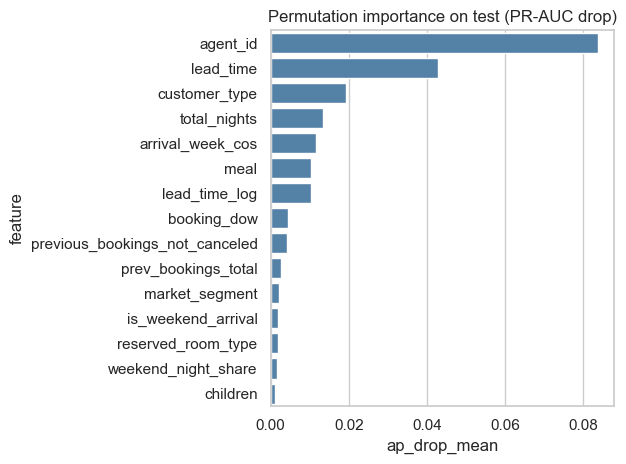

,variable,kind,level,reference,log_odds,odds_ratio
0,agent_top,categorical (vs reference),9,none,0.964,2.623
1,customer_type,categorical (vs reference),Transient-Party,Transient,-0.865,0.421
2,agent_top,categorical (vs reference),28,none,-0.677,0.508
3,customer_type,categorical (vs reference),Contract,Transient,-0.668,0.513
4,customer_type,categorical (vs reference),Group,Transient,-0.615,0.540
5,meal,categorical (vs reference),SC,BB,0.436,1.547
6,agent_top,categorical (vs reference),7,none,-0.427,0.653
7,prev_cancel_ratio,numeric (per +1 SD),+1 SD,1 SD lower (SD = 0.135),0.423,1.526
8,agent_top,categorical (vs reference),22,none,-0.351,0.704
9,agent_top,categorical (vs reference),83,none,0.339,1.403


Reference categories: {'market_segment': 'Online TA', 'distribution_channel': 'TA/TO', 'customer_type': 'Transient', 'reserved_room_type': 'A', 'meal': 'BB', 'arrival_dow': 'Monday', 'agent_top': 'none'}. Example: Transient-Party vs Transient = 0.42 (i.e. Transient vs Transient-Party = 2.38). Odds, not probabilities; association, not cause.


In [18]:
X_test = test[FEATURES]
imp = permutation_importance(final_pipe, X_test, y_test, scoring='average_precision', n_repeats=5, random_state=SEED, n_jobs=1)
IMPORTANCE = pd.DataFrame({'feature': FEATURES, 'ap_drop_mean': imp.importances_mean, 'ap_drop_std': imp.importances_std}
                          ).sort_values('ap_drop_mean', ascending=False)
display(IMPORTANCE.head(15).round(4))
sns.barplot(data=IMPORTANCE.head(15), x='ap_drop_mean', y='feature', color='steelblue')
plt.title('Permutation importance on test (PR-AUC drop)'); plt.tight_layout(); plt.show()

lr = fm.build_pipeline('logistic_regression', NUM, CAT, BEST['logistic_regression'], seed=SEED, top_agents=CONFIG['top_agents'])
fm.fit_pipeline(lr, fit_final, FEATURES, CONFIG['fit_date_final'], BEST['logistic_regression'].get('half_life_days', 0))
lr_prep = lr.named_steps['preprocess']
coef = pd.Series(lr.named_steps['model'].coef_[0], index=lr_prep.get_feature_names_out())
sd = lr_prep.named_transformers_['num'].named_steps['scale'].scale_
odds_rows = [{'variable': c, 'kind': 'numeric (per +1 SD)', 'level': '+1 SD', 'reference': f'1 SD lower (SD = {s:.3g})',
              'log_odds': coef[f'num__{c}']} for c, s in zip(NUM, sd)]
REFERENCE = {v: str(fit_final[v].mode().iloc[0]) for v in CAT}
REFERENCE['agent_top'] = 'none'
for prefix, v in [('cat__', v) for v in CAT] + [('agent__', 'agent_top')]:
    terms = coef[coef.index.str.startswith(f'{prefix}{v}_')]
    terms.index = terms.index.str[len(prefix) + len(v) + 1:]
    ref = REFERENCE[v]
    assert ref in terms.index, f'reference {ref} of {v} not among the encoded categories'
    odds_rows += [{'variable': v, 'kind': 'categorical (vs reference)', 'level': lev, 'reference': ref, 'log_odds': b - terms[ref]}
                  for lev, b in terms.items() if lev not in (ref, 'infrequent_sklearn')]
ODDS_ALL = pd.DataFrame(odds_rows)
ODDS_ALL['odds_ratio'] = np.exp(ODDS_ALL['log_odds'])
ODDS = ODDS_ALL.reindex(ODDS_ALL['log_odds'].abs().sort_values(ascending=False).index).head(15).reset_index(drop=True)
display(ODDS.round(3))
ct = ODDS_ALL.query("variable == 'customer_type'").set_index('level')['odds_ratio']
print(f"Reference categories: {REFERENCE}. Example: Transient-Party vs Transient = {ct.get('Transient-Party', np.nan):.2f} "
      f"(i.e. Transient vs Transient-Party = {1 / ct.get('Transient-Party', np.nan):.2f}). Odds, not probabilities; association, not cause.")

## 10. F3 — Business translation: who to contact, how much revenue is in the queue
- `gross_value` = ADR × nights (real data, snapshot ADR). `syn_net_booking_value` = contribution (gross × (1 − commission) − room cost × nights) — **simulated** assumptions (notebook 03 §2.6). Individual bookings are 99.96% No Deposit, so the deposit-retention sensitivity of F1 design §6 does not change these rankings.
- **Revenue capture** (ranking by expected loss p × value vs by p alone at the same queue size) is computed on the **retrospective arrival cohort** (cohort top k, k = ceil(share × n)).
- **Tiers** are those of the **operational weekly queue** (§7.1, canonical table).
- These are cancellations and revenue **reached** in a retrospective evaluation, not cancellations **avoided**: the effect of contacting a guest comes from the G1 scenario assumption and a pilot with a holdout group (README §5.3).

In [19]:
def capture(order_score, value, share):
    k = int(np.ceil(share * len(test))); o = np.lexsort((tie_test, -order_score))[:k]
    lost = value * y_test
    return lost[o].sum() / lost.sum(), y_test[o].mean()
gross = test['gross_value'].to_numpy(); contrib = test['syn_net_booking_value'].to_numpy()
cap = []
for share in CONFIG['capacity_shares']:
    for basis, value in [('gross EUR (real)', gross), ('contribution EUR (simulated)', contrib)]:
        for rank_name, s in [('p_cancel', p_test), ('expected loss p x value', p_test * value),
                             ('segment x lead rule', TEST_SCORES['rule_segment_x_leadband']), ('random', np.random.default_rng(SEED).random(len(test)))]:
            c, prec = capture(s, value, share)
            cap.append({'queue_share': share, 'value_basis': basis, 'ranking': rank_name, 'share_of_cancelled_value_reached': c, 'precision': prec})
CAPTURE = pd.DataFrame(cap)
display(CAPTURE.pivot_table(index=['value_basis', 'ranking'], columns='queue_share', values='share_of_cancelled_value_reached').round(3))

test['expected_revenue_at_risk'] = test['p_cancel'] * test['gross_value']
QI['lost_gross'] = QI['gross_value'] * QI['is_canceled']
TIERS = QI.groupby('risk_tier').agg(bookings=('p_cancel', 'size'), mean_p=('p_cancel', 'mean'), cancel_rate=('is_canceled', 'mean'),
                                    cancellations=('is_canceled', 'sum'), cancelled_gross_eur=('lost_gross', 'sum'))
TIERS['share_bookings'] = TIERS['bookings'] / len(QI)
TIERS['share_cancelled_gross'] = TIERS['cancelled_gross_eur'] / TIERS['cancelled_gross_eur'].sum()
TIERS['decision_rule'] = TIERS.index.map({'high': 'I3 phone call (I5 if <= 7 days)', 'medium': 'I2 personalised reminders', 'low': 'I1 standard confirmation'})
TIERS = TIERS.reindex(['high', 'medium', 'low'])
print('Tiers of the operational weekly queue 2017:')
display(TIERS.round(3))
display(pd.crosstab(QI['market_segment'], QI['risk_tier'], normalize='index').reindex(columns=['high', 'medium', 'low']).round(3))

queue_share                                            0.05   0.10   0.20
value_basis                  ranking                                     
contribution EUR (simulated) expected loss p x value  0.240  0.357  0.524
                             p_cancel                 0.157  0.236  0.398
                             random                   0.051  0.094  0.199
                             segment x lead rule      0.079  0.162  0.300
gross EUR (real)             expected loss p x value  0.236  0.355  0.522
                             p_cancel                 0.161  0.242  0.405
                             random                   0.051  0.094  0.199
                             segment x lead rule      0.081  0.167  0.308

Tiers of the operational weekly queue 2017:


,bookings,mean_p,cancel_rate,cancellations,cancelled_gross_eur,share_bookings,share_cancelled_gross,decision_rule
risk_tier,,,,,,,,
high,587,0.565,0.462,271,243584.50,0.049,0.169,I3 phone call (I5 if <= 7 days)
medium,1821,0.479,0.394,718,356119.25,0.150,0.247,I2 personalised reminders
low,9694,0.276,0.198,1921,844690.33,0.801,0.585,I1 standard confirmation


risk_tier,high,medium,low
market_segment,,,
Aviation,0.147,0.000,0.853
Complementary,0.000,0.000,1.000
Corporate,0.003,0.000,0.997
Direct,0.005,0.002,0.992
Offline TA/TO,0.000,0.000,1.000
Online TA,0.064,0.203,0.732


### 10.1 Action queue and dated schedule (decision table §2–3)
Every eligible queued booking gets its rule **at its decision time**: high and 8+ days → I3 phone call; high and ≤ 7 days → I5 (no guest action, counted in the date × room-type buffer); medium and 8+ days → I2 personalised reminders; otherwise I1 standard confirmation. Group-block bookings go to the capacity track (G2, revenue-manager approval).

The schedule lists each dated action and never schedules one before the decision time: I2 reminders at 30 and 14 days before arrival; a booking that enters the band after a milestone has passed gets **one reminder immediately**, then the remaining milestones (max 2 messages); the I1 reminder 7 days before arrival is dropped when that date is not after the decision time. The executor (n8n, G2) must still re-check at execution time that the booking is active and that the guest has not answered or opted out (consent / open actions are unknown in this extract). `action_queue_2017.csv` = proposals, one row per booking, joined from the canonical score table; `action_schedule_2017.csv` = dated actions. The outcome column is known only later and is shown for evaluation.

In [20]:
# Edge cases of the schedule rule (days to arrival at the decision time) -> expected number of dated actions
EXPECTED = {3: {'I1': 1, 'I2': 1}, 8: {'I1': 2, 'I2': 1}, 13: {'I1': 2, 'I2': 1}, 14: {'I1': 2, 'I2': 1}, 29: {'I1': 2, 'I2': 2}, 30: {'I1': 2, 'I2': 2}}
d0 = pd.Timestamp('2017-03-05')
sched_args = (CONFIG['i2_milestones_days'], CONFIG['i1_reminder_days'], CONFIG['i2_max_messages'])
for days, exp in EXPECTED.items():
    for rule_id in ['I1', 'I2', 'I3', 'I5']:
        rows = fm.schedule_actions(0, d0, d0 + pd.Timedelta(days=days), rule_id, *sched_args)
        assert all(d0 <= r['scheduled_at'] < d0 + pd.Timedelta(days=days) for r in rows), (days, rule_id)
        assert len(rows) == {'I3': 1, 'I5': 0, **exp}[rule_id], (days, rule_id, rows)

sched = [r for b, t, a, rule_id in zip(QI['booking_id'], QI['score_time'], QI['arrival_date'], QI['rule'])
         for r in fm.schedule_actions(b, t, a, rule_id, *sched_args)]
ACTION_SCHEDULE = pd.DataFrame(sched)
ACTION_SCHEDULE.insert(0, 'run_id', RUN_ID)
arrival_of = QI.set_index('booking_id')['arrival_date']
assert ACTION_SCHEDULE['scheduled_at'].ge(ACTION_SCHEDULE['decision_at']).all(), 'action scheduled before its decision time'
assert ACTION_SCHEDULE['scheduled_at'].lt(ACTION_SCHEDULE['booking_id'].map(arrival_of)).all()
assert ACTION_SCHEDULE[ACTION_SCHEDULE['rule'].eq('I2')].groupby('booking_id').size().le(CONFIG['i2_max_messages']).all()
assert QI.loc[QI['rule'].isin(['I3', 'I5']), 'risk_tier'].eq('high').all() and QI.loc[QI['risk_tier'].eq('high'), 'rule'].isin(['I3', 'I5']).all()
assert QI.loc[QI['rule'].eq('I2'), 'risk_tier'].eq('medium').all()

item = ACTION_SCHEDULE['action_type'] + ' ' + ACTION_SCHEDULE['scheduled_at'].dt.strftime('%Y-%m-%d')
plan_text = item.groupby(ACTION_SCHEDULE['booking_id']).agg('; '.join)
SCORES['scheduled_actions'] = SCORES['booking_id'].map(plan_text).fillna('')
SCORES.loc[SCORES['rule'].eq('I5'), 'scheduled_actions'] = 'none: count in date x room-type cancellation buffer'
SCORES.loc[SCORES['rule'].eq('G2'), 'scheduled_actions'] = 'count in date x room-type release buffer (capacity_allocation / resale)'
SCORES['needs_approval'] = SCORES['rule'].eq('G2')
AQ_COLS = ['run_id', 'track', 'booking_id', 'score_time', 'booking_date', 'arrival_date', 'days_to_arrival', 'market_segment', 'customer_type',
           'lead_time', 'total_nights', 'gross_value', 'model_version', 'p_cancel', 'expected_revenue_at_risk', 'risk_tier', 'rule', 'owner',
           'approval', 'needs_approval', 'scheduled_actions', 'created_by_decision', 'arrival_after_decision', 'active_at_decision',
           'not_complimentary', 'consent_status', 'open_action_check', 'is_canceled']
ACTION_QUEUE = (SCORES[AQ_COLS].rename(columns={'is_canceled': 'outcome_label_known_later'})
                .sort_values(['score_time', 'track', 'booking_id']).reset_index(drop=True))

i2 = QI['rule'].eq('I2')
immediate = ACTION_SCHEDULE['schedule_reason'].str.startswith('immediate')
SCHEDULE_SUMMARY = pd.Series({
    'queued individual bookings': len(QI),
    'I3 phone call': int(QI['rule'].eq('I3').sum()), 'I5 buffer (<= 7 days)': int(QI['rule'].eq('I5').sum()),
    'I2 reminders': int(i2.sum()), 'I1 standard': int(QI['rule'].eq('I1').sum()), 'G2 group capacity track': len(QG),
    'I2 entered after the 30-day mark (immediate reminder)': int(ACTION_SCHEDULE.loc[immediate, 'booking_id'].nunique()),
    'I2 with 8-14 days left (one message only)': int((i2 & QI['days_to_arrival'].le(14)).sum()),
    'I1 without the 7-day reminder (date not after the decision time)': int((QI['rule'].eq('I1') & QI['days_to_arrival'].le(CONFIG['i1_reminder_days'])).sum()),
    'dated actions in the schedule': len(ACTION_SCHEDULE)}, name='count')
display(SCHEDULE_SUMMARY.to_frame())
display(pd.crosstab(SCORES['rule'], SCORES['risk_tier'].fillna('group track'), margins=True))

rng = np.random.default_rng(SEED)
picks = []
for rule_id, n in [('I3', 4), ('I5', 2), ('I2', 3), ('I1', 3)]:
    part = ACTION_QUEUE[ACTION_QUEUE['rule'].eq(rule_id)]
    picks.append(part.iloc[np.sort(rng.choice(len(part), size=min(n, len(part)), replace=False))])
SAMPLE = pd.concat(picks)[['booking_id', 'score_time', 'booking_date', 'arrival_date', 'days_to_arrival', 'market_segment', 'gross_value',
                           'p_cancel', 'risk_tier', 'rule', 'scheduled_actions', 'outcome_label_known_later']].reset_index(drop=True)
SAMPLE['outcome (known later)'] = SAMPLE.pop('outcome_label_known_later').map({1: 'cancelled', 0: 'stayed'})
for c in ['score_time', 'booking_date', 'arrival_date']:
    SAMPLE[c] = SAMPLE[c].dt.date
SAMPLE[['p_cancel', 'gross_value']] = SAMPLE[['p_cancel', 'gross_value']].round(2)
display(SAMPLE)

,count
queued individual bookings,12102
I3 phone call,576
I5 buffer (<= 7 days),11
I2 reminders,1803
I1 standard,9712
G2 group capacity track,1054
I2 entered after the 30-day mark (immediate reminder),276
I2 with 8-14 days left (one message only),54
I1 without the 7-day reminder (date not after the decision time),1388
dated actions in the schedule,22164


risk_tier,group track,high,low,medium,All
rule,,,,,
G2,1054,0,0,0,1054
I1,0,0,9694,18,9712
I2,0,0,0,1803,1803
I3,0,576,0,0,576
I5,0,11,0,0,11
All,1054,587,9694,1821,13156


,booking_id,score_time,booking_date,arrival_date,days_to_arrival,market_segment,gross_value,p_cancel,risk_tier,rule,scheduled_actions,outcome (known later)
0,75304,2017-01-08,2017-01-02,2017-06-28,171,Online TA,653.38,0.57,high,I3,phone_call 2017-01-08,stayed
1,26524,2017-02-19,2017-02-15,2017-04-21,61,Online TA,1569.60,0.63,high,I3,phone_call 2017-02-19,cancelled
2,33092,2017-04-02,2017-04-02,2017-08-15,135,Online TA,1560.00,0.51,high,I3,phone_call 2017-04-02,cancelled
3,74532,2017-04-30,2017-04-28,2017-06-23,54,Online TA,260.00,0.50,high,I3,phone_call 2017-04-30,stayed
4,65466,2017-01-22,2017-01-20,2017-01-25,3,Online TA,3791.00,0.72,high,I5,none: count in date x room-type cancellation b...,stayed
5,68088,2017-03-12,2017-03-09,2017-03-15,3,Online TA,1664.00,0.52,high,I5,none: count in date x room-type cancellation b...,stayed
6,27389,2017-03-05,2017-03-05,2017-05-03,59,Online TA,1228.00,0.51,medium,I2,reminder 2017-04-03; reminder 2017-04-19,cancelled
7,72137,2017-04-23,2017-04-17,2017-05-19,26,Online TA,320.00,0.49,medium,I2,reminder 2017-04-23; reminder 2017-05-05,stayed
8,33596,2017-07-23,2017-07-17,2017-08-29,37,Online TA,549.00,0.43,medium,I2,reminder 2017-07-30; reminder 2017-08-15,cancelled
9,66687,2017-01-15,2017-01-15,2017-02-26,42,Online TA,408.00,0.34,low,I1,confirm_email 2017-01-15; reminder 2017-02-19,stayed


## 11. F3 — Group track, whole-hotel view and a retrospective aggregate
`group_block` (Groups, Non Refund or block size ≥ 5) gets a **rule**, not ML: the historical cancellation rate per market segment × deposit type, fitted on arrivals ≤ 2016-12-31 (§7, stored in the bundle). Combined with the individual model this gives one risk score per booking for the whole City Hotel (retrospective arrival cohort below). A high group AUC is a **ranking** result (mostly Non Refund vs the rest); it does not mean that almost every group booking cancels — use the cancellation rate, the contracts and the release deadlines for that.

**Sum of p per arrival day / week.** A retrospective check of the probabilities in aggregate, in **bookings**. It is **not** a forecast of rooms that can be resold: there is no forecast origin (it uses every booking of the arrival cohort, including bookings not yet created and bookings already cancelled at any realistic decision date), and bookings are not converted into rooms / room-nights by stay date × room type. An operational capacity forecast (G1) needs an origin and horizon, the separation of cancellations already known, a treatment of bookings not yet created and an allocation to stay date × room type, evaluated against a baseline on the same contract. The constant-rate baseline here uses the training cancellation rate **of the same population**.

,bookings,cancel_rate,roc_auc,pr_auc,precision@20%,lift@20%
scope,,,,,,
individual (model),20399,0.3437,0.7356,0.5556,0.5831,1.6963
group_block (rule),6997,0.6667,0.9346,0.9636,1.0000,1.4999
whole City Hotel 2017 (two-track system),27396,0.4262,0.8196,0.8069,0.8891,2.0858


Retrospective aggregate per arrival period (no forecast origin; not a room forecast):


,level,scope,unit,periods,mean_actual_cancelled_bookings,MAE_sum_of_p,constant_rate_same_population,MAE_constant_rate,WAPE_sum_of_p,corr_sum_of_p
0,day,individual,bookings (not rooms / room-nights),243,28.856,4.137,0.280,6.728,0.143,0.912
1,day,whole hotel,bookings (not rooms / room-nights),243,48.053,5.239,0.415,12.223,0.109,0.977
2,week,individual,bookings (not rooms / room-nights),36,194.778,14.103,0.280,36.848,0.072,0.976
3,week,whole hotel,bookings (not rooms / room-nights),36,324.361,16.578,0.415,41.674,0.051,0.989


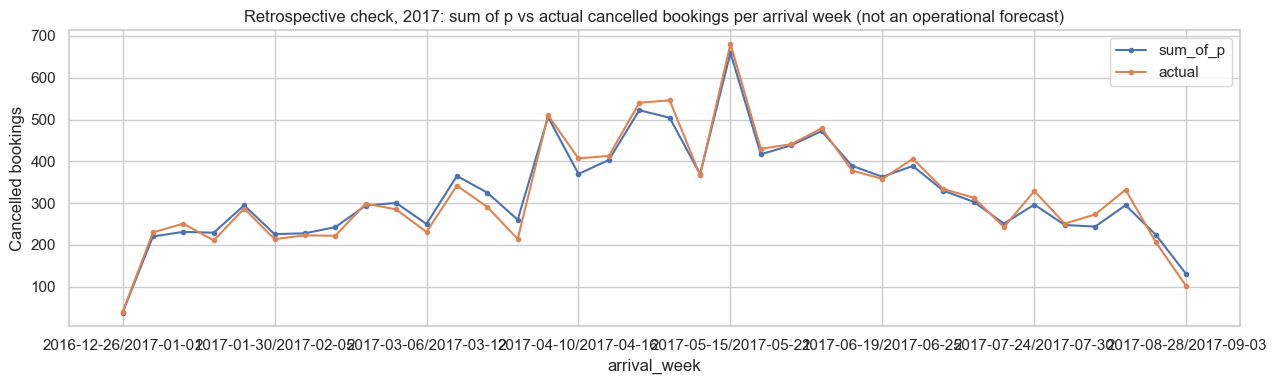

In [21]:
grp_test = grp[is_test(grp)].copy()
grp_test['p_cancel'] = group_rule.predict(grp_test)
y_g = grp_test['is_canceled'].to_numpy()
all_test = pd.concat([test.assign(track='individual model'), grp_test.assign(track='group rule')])
y_all, p_all = all_test['is_canceled'].to_numpy(), all_test['p_cancel'].to_numpy()
SYSTEM = pd.DataFrame([
    {'scope': 'individual (model)', 'bookings': len(test), 'cancel_rate': y_test.mean(), **fm.metric_bundle(y_test, p_test, tie_breaker=tie_test)},
    {'scope': 'group_block (rule)', 'bookings': len(grp_test), 'cancel_rate': y_g.mean(),
     **fm.metric_bundle(y_g, grp_test['p_cancel'].to_numpy(), tie_breaker=grp_test['tie'].to_numpy())},
    {'scope': 'whole City Hotel 2017 (two-track system)', 'bookings': len(all_test), 'cancel_rate': y_all.mean(),
     **fm.metric_bundle(y_all, p_all, tie_breaker=all_test['tie'].to_numpy())},
]).set_index('scope')
display(SYSTEM[['bookings', 'cancel_rate', 'roc_auc', 'pr_auc', 'precision@20%', 'lift@20%']].round(4))

fit_all = pd.concat([fit_final, grp_fit])
NAIVE_RATE = {'individual': fit_final['is_canceled'].mean(), 'whole hotel': fit_all['is_canceled'].mean()}   # same population as the scope
AGGREGATE = []
for level, col in [('day', 'arrival_date'), ('week', 'arrival_week')]:
    for scope, frame in [('individual', all_test[all_test['track'].eq('individual model')]), ('whole hotel', all_test)]:
        a = frame.groupby(col).agg(expected=('p_cancel', 'sum'), actual=('is_canceled', 'sum'), n=('p_cancel', 'size'))
        AGGREGATE.append({'level': level, 'scope': scope, 'unit': 'bookings (not rooms / room-nights)', 'periods': len(a),
                          'mean_actual_cancelled_bookings': a['actual'].mean(), 'MAE_sum_of_p': (a['expected'] - a['actual']).abs().mean(),
                          'constant_rate_same_population': NAIVE_RATE[scope],
                          'MAE_constant_rate': (a['n'] * NAIVE_RATE[scope] - a['actual']).abs().mean(),
                          'WAPE_sum_of_p': (a['expected'] - a['actual']).abs().sum() / a['actual'].sum(),
                          'corr_sum_of_p': np.corrcoef(a['expected'], a['actual'])[0, 1]})
AGGREGATE = pd.DataFrame(AGGREGATE)
print('Retrospective aggregate per arrival period (no forecast origin; not a room forecast):')
display(AGGREGATE.round(3))
wk = all_test.groupby('arrival_week').agg(sum_of_p=('p_cancel', 'sum'), actual=('is_canceled', 'sum'))
ax = wk.plot(figsize=(13, 4), marker='.', title='Retrospective check, 2017: sum of p vs actual cancelled bookings per arrival week (not an operational forecast)')
ax.set_ylabel('Cancelled bookings'); plt.tight_layout(); plt.show()

## 12. Outputs and hand-over to G
Every run writes to `artifacts/modeling/runs/<run_id>/`; at the end the run's files replace the top-level copies in `artifacts/modeling/` (the latest run), so files of two runs are never mixed.

| File | Content | View |
|---|---|---|
| `final_model_bundle.joblib` | model + calibrator + features + population rule + group rule + fit date / selection cutoff + policy + eligibility checks; score with `fm.score_bookings` (two tracks) or `fm.score` (individual model only) | — |
| `risk_scores.csv` | shape of `hotel.risk_scores`: one row per eligible booking of the **operational weekly queue 2017** (`scored_at` = decision time, after the fit date; `model_version` = run id; tier only for the individual track) | operational simulation |
| `action_queue_2017.csv`, `action_schedule_2017.csv`, `sample_decisions.csv` | proposals per queued booking (rule, owner, approval, eligibility incl. unknown consent / open action) and the dated actions; 12-booking illustration | operational simulation |
| `policy_test.csv`, `policy_queue_diff.csv`, `queue_contract.csv`, `tiers_queue.csv`, `workload_by_month.csv` | weekly policy vs rule on the same batches (paired batch bootstrap), eligibility counts, tiers, workload by decision month | operational simulation |
| `oof_predictions_2016.csv`, `test_predictions_2017.csv` | per-booking predictions with labels; `test_predictions_2017.csv` carries the queue tier joined from the canonical table (empty when the booking was not in the queue) | evaluation |
| `model_comparison_oof.csv`, `optuna_trials.csv`, `calibration_choice.csv`, `test_metrics.csv`, `model_vs_rules.csv`, `precision_recall_f1.csv`, `deciles_test.csv`, `monthly_test.csv`, `subgroups_test.csv`, `robustness.csv`, `pre_arrival_selection.csv`, `pre_arrival_cancellation_timing.csv`, `revenue_capture.csv`, `system_view.csv`, `cancellation_aggregate_retrospective.csv`, `feature_importance.csv`, `odds_ratios.csv`, `staffing_2016.csv`, `agent_mapping_test.csv` | tables of sections 1–11 | evaluation (retrospective) |
| `output_consistency.csv` | cross-file checks: same p / tier / rule / run for the same `booking_id` + `score_time` | — |
| `model_report.md`, `manifest.json` | readable summary and run manifest (config, environment, data and code hashes, contracts, files) | — |

**Pseudo-pipeline F → G:** new bookings of the week → features (as in notebook 03) → at the week's close `score_bookings()` (population, eligibility, time checks) → weekly ranking (floor slots) → `risk_tier` (+ `expected_revenue_at_risk`) → `risk_scores` → decision table rules I1–I3/I5 with a dated schedule (individual) and G1–G5 (group capacity track) → staff approval where required → n8n re-checks status / response / opt-out at execution → `interventions` → KPIs (M3–M6 for the model; B/C KPIs by pilot arm).

In [22]:
import hashlib, shutil
def sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()[:16]
DATE = '%Y-%m-%d'
RISK_SCORES = pd.DataFrame({'booking_id': SCORES['booking_id'], 'scored_at': SCORES['score_time'], 'model_version': SCORES['model_version'],
                            'p_cancel': SCORES['p_cancel'].round(4), 'risk_tier': SCORES['risk_tier'],
                            'expected_revenue_at_risk': SCORES['expected_revenue_at_risk'].round(2),
                            'days_to_arrival': SCORES['days_to_arrival'].astype(int)})
assert not RISK_SCORES.duplicated(['booking_id', 'scored_at']).any() and RISK_SCORES['p_cancel'].between(0, 1).all()
assert RISK_SCORES['risk_tier'].dropna().isin(['low', 'medium', 'high']).all()
assert RISK_SCORES['scored_at'].gt(pd.Timestamp(BUNDLE['fit_date'])).all(), 'operational score before the model existed'
RISK_SCORES.to_csv(OUT / 'risk_scores.csv', index=False, date_format=DATE)
ACTION_QUEUE.to_csv(OUT / 'action_queue_2017.csv', index=False, date_format=DATE)
ACTION_SCHEDULE.to_csv(OUT / 'action_schedule_2017.csv', index=False, date_format=DATE)

OOF.assign(p_cancel=p_sel)[['booking_id', 'arrival_date', 'fold', 'is_canceled', 'p_cancel']].to_csv(OUT / 'oof_predictions_2016.csv', index=False, date_format=DATE)
TEST_PRED = test[['booking_id', 'booking_date', 'arrival_date', 'market_segment', 'lead_time', 'gross_value', 'is_canceled', 'p_cancel',
                  'risk_decile', 'cohort_top20', 'expected_revenue_at_risk']].merge(
    SCORES.loc[SCORES['track'].eq('individual model'), ['booking_id', 'score_time', 'risk_tier', 'rule']].rename(
        columns={'score_time': 'queue_score_time', 'risk_tier': 'queue_risk_tier', 'rule': 'queue_rule'}),
    on='booking_id', how='left', validate='one_to_one')
TEST_PRED.insert(0, 'run_id', RUN_ID)
TEST_PRED.to_csv(OUT / 'test_predictions_2017.csv', index=False, date_format=DATE)

tables = {'model_comparison_oof': COMPARISON, 'optuna_trials': TRIALS, 'test_metrics': TEST_METRICS, 'model_vs_rules': DIFFS,
          'policy_test': POLICY_TEST, 'policy_queue_diff': POLICY_DIFF, 'queue_contract': CONTRACT, 'deciles_test': DECILES,
          'monthly_test': MONTHLY, 'subgroups_test': SUBGROUPS, 'robustness': ROBUST, 'pre_arrival_selection': PRE_SEL,
          'pre_arrival_cancellation_timing': PRE_TIMING, 'calibration_choice': CAL_TABLE, 'revenue_capture': CAPTURE, 'tiers_queue': TIERS,
          'system_view': SYSTEM, 'cancellation_aggregate_retrospective': AGGREGATE, 'feature_importance': IMPORTANCE, 'odds_ratios': ODDS,
          'precision_recall_f1': PRF, 'workload_by_month': WORKLOAD, 'staffing_2016': STAFFING, 'agent_mapping_test': AGENT_TEST,
          'sample_decisions': SAMPLE}
for name, t in tables.items():
    t.to_csv(OUT / f'{name}.csv', index=not isinstance(t.index, pd.RangeIndex), date_format=DATE)

# Cross-file consistency (Fv3-02): the same booking_id + score_time + run_id has the same p / tier / rule everywhere
rs_f = pd.read_csv(OUT / 'risk_scores.csv'); aq_f = pd.read_csv(OUT / 'action_queue_2017.csv')
sc_f = pd.read_csv(OUT / 'action_schedule_2017.csv'); tp_f = pd.read_csv(OUT / 'test_predictions_2017.csv')
m1 = aq_f.merge(rs_f, left_on=['booking_id', 'score_time'], right_on=['booking_id', 'scored_at'], suffixes=('', '_rs'), validate='one_to_one')
m2 = tp_f.dropna(subset=['queue_risk_tier']).merge(aq_f, left_on=['booking_id', 'queue_score_time'], right_on=['booking_id', 'score_time'],
                                                   suffixes=('_tp', '_aq'), validate='one_to_one')
m3 = sc_f.merge(aq_f, left_on=['booking_id', 'decision_at'], right_on=['booking_id', 'score_time'], suffixes=('_sc', '_aq'), validate='many_to_one')
CONSISTENCY = pd.DataFrame([
    {'check': 'risk_scores rows = action_queue rows (same booking_id + score_time)', 'passed': len(m1) == len(aq_f) == len(rs_f)},
    {'check': 'risk_scores p_cancel = action_queue p_cancel (4 dp)', 'passed': bool(np.allclose(m1['p_cancel'].round(4), m1['p_cancel_rs'], atol=1e-9))},
    {'check': 'risk_scores risk_tier = action_queue risk_tier', 'passed': bool(m1['risk_tier'].fillna('-').eq(m1['risk_tier_rs'].fillna('-')).all())},
    {'check': 'risk_scores model_version = action_queue model_version', 'passed': bool(m1['model_version'].eq(m1['model_version_rs']).all())},
    {'check': 'test_predictions queue rows = individual queue rows', 'passed': len(m2) == int(aq_f['track'].eq('individual model').sum())},
    {'check': 'test_predictions p / tier / rule = action_queue', 'passed': bool(np.allclose(m2['p_cancel_tp'], m2['p_cancel_aq'])
                                                                                 and m2['queue_risk_tier'].eq(m2['risk_tier']).all()
                                                                                 and m2['queue_rule'].eq(m2['rule']).all())},
    {'check': 'schedule rows join the queue on booking_id + decision time, same rule and run', 'passed': len(m3) == len(sc_f)
        and bool(m3['rule_sc'].eq(m3['rule_aq']).all()) and bool(m3['run_id_sc'].eq(m3['run_id_aq']).all())},
    {'check': 'no action scheduled before its decision time', 'passed': bool((pd.to_datetime(sc_f['scheduled_at']) >= pd.to_datetime(sc_f['decision_at'])).all())},
    {'check': 'single run_id in every output', 'passed': set(aq_f['run_id']) == set(sc_f['run_id']) == set(tp_f['run_id']) == {RUN_ID}},
])
display(CONSISTENCY)
assert CONSISTENCY['passed'].all(), 'outputs disagree'
CONSISTENCY.to_csv(OUT / 'output_consistency.csv', index=False)

def md(t):
    t = t.round(4).reset_index() if not isinstance(t.index, pd.RangeIndex) else t.round(4)
    head = '| ' + ' | '.join(map(str, t.columns)) + ' |'
    sep = '|' + '---|' * len(t.columns)
    body = ['| ' + ' | '.join('' if pd.isna(v) else str(v) for v in r) + ' |' for r in t.itertuples(index=False)]
    return chr(10).join([head, sep, *body])
hl = SYSTEM.loc['whole City Hotel 2017 (two-track system)']
tm = TEST_METRICS.loc['final_model']
cap_g = CAPTURE.query("queue_share == 0.2 and value_basis == 'gross EUR (real)'").set_index('ranking')['share_of_cancelled_value_reached']
pq, pr_ = POLICY_TEST.iloc[0], POLICY_TEST.iloc[2]
dq = POLICY_DIFF[POLICY_DIFF['policy'].str.startswith('top 20%') & POLICY_DIFF['metric'].eq('tp')].iloc[0]
report = f"""# Model report — stage F (notebook 04, {CONFIG['model_version']}, run {RUN_ID})

Two views are reported and never mixed: the **retrospective arrival-cohort evaluation** (evaluation only) and the **operational weekly-queue simulation** (decision at the end of the booking week, model fitted and selected by {CONFIG['fit_date_final']}; source of `risk_scores.csv`, tiers and actions). Data are a near-arrival snapshot; the 2017 cohort is a partially explored holdout.

## Headline — retrospective arrival cohort (test 2017)
- Individual bookings (model `{SELECTED}`, {len(test):,} bookings, cancellation rate {y_test.mean():.1%}): ROC-AUC **{tm['roc_auc']:.3f}**, average precision ("PR-AUC") {tm['pr_auc']:.3f}, Brier {tm['brier']:.4f} (constant {TEST_METRICS.loc['constant (train rate)', 'brier']:.4f}).
- Cohort top 20% (k = {k20:,}): precision **{tm['precision@20%']:.1%}**, lift **{tm['lift@20%']:.2f}**; it reaches **{cap_g['p_cancel']:.1%}** of cancelled gross value ranked by p and **{cap_g['expected loss p x value']:.1%}** ranked by expected loss (random: 20%).
- Versus the segment × lead-time rule, cohort top 20%: +{caught['final_model'] - caught['rule_segment_x_leadband']} cancellations reached (paired block bootstrap CI in `model_vs_rules.csv`; applies to this cohort ranking only).
- Whole City Hotel (individual model + group rule, {len(all_test):,} bookings): ROC-AUC **{hl['roc_auc']:.3f}** (a ranking metric), PR-AUC {hl['pr_auc']:.3f}, lift@20% {hl['lift@20%']:.2f}.

## Operational weekly queue 2017 (simulation)
- Eligible individual bookings in the queue: {len(QI):,} in {QI['booking_week'].nunique()} weekly batches (cancellation rate {y_q.mean():.1%}); {len(QG):,} group bookings to the capacity track. Eligibility and the bookings not scored because they were created before the model existed: `queue_contract.csv`. Consent and open actions are unknown in the data.
- Top 20% per weekly batch (floor slots): {int(pq['alerts']):,} alerts, precision **{pq['precision']:.1%}**, recall {pq['recall']:.1%} (ceiling {pq['recall_ceiling']:.1%}), lift {pq['lift']:.2f}. Rule ranked in the same batches: precision {pr_['precision']:.1%}; difference {int(dq['model_minus_rule']):+d} cancellations reached (95% CI [{dq['ci_low']:.0f}; {dq['ci_high']:.0f}], whole-batch bootstrap).

## Choices (all made before opening test)
- Folds: {', '.join(f['name'] + ' fit ' + f['fit_date'] for f in FOLDS)}; final fit {CONFIG['fit_date_final']}.
- Model: {SELECTED} {json.dumps(SELECTED_PARAMS)}; calibration: {CALIBRATION} (fold 3 was also part of the tuning objective).
- Policy: decision at the end of the booking week; high = top {CONFIG['tier_high_share']:.0%}, medium = next to {CONFIG['tier_medium_share']:.0%}, slots = {CONFIG['capacity_rounding']}(share × batch); ties by booking_id hash.
- `pre_arrival` branches: own selection on labels known by the branch cutoff (`pre_arrival_selection.csv`).

## Model comparison (2016 out-of-fold)
{md(COMPARISON[['mean_fold_log_loss', 'brier', 'roc_auc', 'pr_auc', 'precision@20%', 'lift@20%']])}

## Test metrics (retrospective cohort)
{md(TEST_METRICS[['test_cancel_rate', 'roc_auc', 'pr_auc', 'brier', 'precision@20%', 'lift@20%', 'recall@20%']])}

## Operating policy (operational queue; last row = retrospective v3 definition)
{md(POLICY_TEST)}

## Weekly policy, model minus rule (operational queue, paired whole-batch bootstrap, 95% CI)
{md(POLICY_DIFF)}

## Queue contract (eligibility at the decision time)
{md(CONTRACT)}

## Precision, recall, F1 at each operating point
{md(PRF)}

## Staffing (planning estimate from 2016 booking dates)
{md(STAFFING)}

## Workload of the operational queue by decision month
{md(WORKLOAD)}

## Model minus rules, cohort top-k (paired block bootstrap, 95% CI)
{md(DIFFS)}

## Risk deciles (retrospective cohort)
{md(DECILES)}

## Tiers (operational queue)
{md(TIERS)}

## Action schedule summary
{md(SCHEDULE_SUMMARY.to_frame())}

## Sample decisions (outcome known only afterwards)
{md(SAMPLE)}

## Agent-mapping leakage test
{md(AGENT_TEST)}

## Robustness (population and time contract per row)
{md(ROBUST)}

## pre_arrival: own selection per branch
{md(PRE_SEL)}

## Timing of 2017 outcomes after the H mark
{md(PRE_TIMING)}

## Two-track system (retrospective cohort)
{md(SYSTEM[['bookings', 'cancel_rate', 'roc_auc', 'pr_auc', 'precision@20%', 'lift@20%']])}

## Retrospective aggregate: sum of p per arrival day / week (bookings; not a room forecast)
{md(AGGREGATE)}

## Odds ratios (categorical vs a stated reference; numeric per +1 SD)
{md(ODDS)}

## Limitations
- Snapshot features (lead time, party, room type) are last recorded values; even the operational simulation scores them, so it is a retrospective prototype, not a live booking-time system.
- The operational queue covers bookings created in weeks closing after {CONFIG['fit_date_final']}; earlier-created 2017 arrivals would need earlier models. Summer 2017 batches miss bookings for arrivals after 31/08/2017 (end of the extract).
- Fold 3 is in the tuning objective and in the calibration choice; the 2017 cohort is partially explored. Neither makes the test AUC false, but the selection evidence is cross-validated, not independent.
- `lead_time` 0–7 days means booked close to arrival; the subgroup table says nothing about how late a cancellation notice comes.
- Probabilities were kept raw because they had the best pre-test Brier; the decile table shows gaps of a few points, so p × value is an estimate, not an exact loss.
- The sum of p is a retrospective aggregate of bookings without a forecast origin; it is not a forecast of resellable rooms (G1 needs origin, horizon, known cancellations, not-yet-created bookings and stay date × room type).
- Adding `pre_arrival_extra` (special requests and waiting-list fields together) raises AUC also after the eligibility filter; the effect of special requests alone is not isolated and nothing here is causal.
- Configurations not tried, or tried without improvement, do not prove that the data or the method has reached its limit.
- Detected ≠ avoided: the uplift of interventions is a G1 assumption to be measured by a randomised pilot.
"""
(OUT / 'model_report.md').write_text(report, encoding='utf-8')

manifest = {'notebook': 'notebooks/04_modeling_evaluation.ipynb', 'model_version': CONFIG['model_version'], 'run_id': RUN_ID,
            'run_finished': pd.Timestamp.now().isoformat(timespec='seconds'), 'config': CONFIG, 'environment': ENV,
            'selected_model': SELECTED, 'params': SELECTED_PARAMS, 'calibration': CALIBRATION,
            'contracts': {'headline': 'retrospective arrival cohort 2017, population A',
                          'operational_queue': CONFIG['decision_time'] + f"; score_time > fit_date = selection_cutoff = {CONFIG['fit_date_final']}",
                          'pre_arrival': 'own selection per branch on labels known by the branch cutoff',
                          'tie_break': 'fm.id_tie_breaker(booking_id), seed 0', 'capacity_rounding': CONFIG['capacity_rounding']},
            'inputs': {p: sha(ROOT / p) for p in ['data/processed/modeling_dataset.csv', 'data/processed/bookings_prepared.csv', 'config/column_groups.json']},
            'code': {p: sha(ROOT / p) for p in ['src/f_modeling.py', 'src/run_notebooks.py', 'requirements.txt']},
            'outputs': sorted(p.name for p in OUT.iterdir() if p.is_file()) + ['manifest.json']}
(OUT / 'manifest.json').write_text(json.dumps(manifest, indent=2, default=str), encoding='utf-8')
print('Wrote', len(manifest['outputs']), 'files to', OUT)

# Publish this run as the latest: replace the top-level files of artifacts/modeling/ (runs/ is kept)
for old in OUT_ROOT.iterdir():
    if old.is_file():
        old.unlink()
for new in OUT.iterdir():
    shutil.copy2(new, OUT_ROOT / new.name)
assert sorted(p.name for p in OUT_ROOT.iterdir() if p.is_file()) == sorted(p.name for p in OUT.iterdir())
print('Latest run published to', OUT_ROOT)

,check,passed
0,risk_scores rows = action_queue rows (same boo...,True
1,risk_scores p_cancel = action_queue p_cancel (...,True
2,risk_scores risk_tier = action_queue risk_tier,True
3,risk_scores model_version = action_queue model...,True
4,test_predictions queue rows = individual queue...,True
5,test_predictions p / tier / rule = action_queue,True
6,schedule rows join the queue on booking_id + d...,True
7,no action scheduled before its decision time,True
8,single run_id in every output,True


Wrote 34 files to C:\Users\ADMIN\Desktop\BA-Advance-Project---Group-2-main\artifacts\modeling\runs\f-v3.1-2026-10-19_20261020-101915
Latest run published to C:\Users\ADMIN\Desktop\BA-Advance-Project---Group-2-main\artifacts\modeling
